# Figures for *Beyond a Single Southern Annular Mode Pattern*

Authors: Maia Posternack (maiaposternack@gmail.com), Kirstin Koepnick (kirstinkoepnick@g.harvard.edu)

Every figure in the paper and supplement, written to `figures/`. Figure 1 is not generated here, i made it on google slides!

| Figure | File | Section |
|---|---|---|
| 1 | `overview.pdf` | Google Slides |
| 2 | `ensemble_composite.pdf` | 3 |
| 3 | `occupancy_box.pdf` | 3 |
| 4 | `temporal_proj.pdf` | 3 |
| 5 | `scatter.pdf` | 3 |
| 6 | `annularity.pdf` | 3 |
| 7 | `transition.pdf` | 3 |
| 8 | `all_seasons_clusters.pdf` | 2 |
| S1 | `autoencoder_reconstruction.pdf` | 1 |
| S2 | `reconstruction_loss.pdf` | 4 |
| S3 | `latent_sweep_composites.pdf` | 4 |
| S4 | `elbow.pdf` | 1 |
| S5 | `ensemble.pdf` | 3 |
| S6 | `composites_common_colorbar.pdf` | 1 |
| S7 | `corr_direct_clusters_ensemble.pdf` | 3 |
| S8 | `pc1_distributions_by_cluster.pdf` | 1 |
| S9 | `occupancy_matched_composites.pdf` | 1 |
| S10 | `occupancy_matched_difference_maps.pdf` | 1 |
| S11 | `eof1_residual_composites.pdf` | 3 |
| S12 | `baseline_composites.pdf` | 3 |
| S13 | `pca_composites.pdf` | 1 |
| S14 | `pca_elbow.pdf` | 1 |
| S15 | `shuffled_null_test.pdf` | 1 |
| S16 | `pc1_group_transitions.pdf` | 1 |
| S17 | `season_linkages.pdf` | 2 |
| S18 | `seasonal_transition_heatmaps.pdf` | 1 |

## Running

This takes ~25 min and needs the TensorFlow environment (Fig S1 runs the saved autoencoder). Run via

```bash
qsub jobs/figures.pbs
```

## Setup

In [1]:
from pathlib import Path

import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from matplotlib.dates import DateFormatter
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.optimize import linear_sum_assignment
from scipy.stats import gaussian_kde

from functions import (
    FS_LABEL, FS_TICK, FS_ANNOT, PCT, fs_sizes, polar_map, stipple, elbow, heatmap,
    luminance_color, ward, ward_labels, match_clusters, physical_order, coarsen,
    undo_lat_weight, spatial_corr, sam_index, area_weighted_rms, non_annularity,
    transition_matrix, shuffle_null, p_values,
)

SCRATCH = "/glade/derecho/scratch/mposternack"
MODEL_DIR = f"{SCRATCH}/autoencoder_models"
SEED_DIR = f"{MODEL_DIR}/era5_seed_ensemble"
SWEEP_DIR = f"{MODEL_DIR}/era5_latent_sweep"
PCA_ALL_FILE = f"{SCRATCH}/sam_pca_data_all.nc"
PCA_FILE = "data/pca/sam_pca_data.nc"
FIG_DIR = Path("figures")

# tag used when running train_autoencoder.py for the published run
TAG = "sam_autoencoder_1x_64_32_16_8_4_50epochs_cropped"
SEED_TAG = "sam_era5_autoencoder_seed{}"

K = 3
SEEDS = list(range(10))
RNG_SEED = 42
N_SHUFFLE = 1000
CLUSTER_NAMES = ["Low-amplitude SAM$-$", "SAM$+$", "SAM$-$"]
TICKS = ["C1\n(Low-amp.\nSAM$-$)", "C2\n(SAM$+$)\n", "C3\n(SAM$-$)\n"]
SPS = ccrs.SouthPolarStereo()


def load(name, tag=TAG, d=MODEL_DIR):
    return np.load(f"{d}/{name}_{tag}.npy", allow_pickle=True)


def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", format="pdf", bbox_inches="tight",
                metadata={"CreationDate": None})
    plt.show()


pca = xr.open_dataset(PCA_FILE)
eofs, pcs, var_ex = pca["eofs"].values, pca["pcs"].values, pca["variance_explained"].values
pc1 = pcs[:, 0]
pc1_std = (pc1 - pc1.mean()) / pc1.std()

## 1. The published CAE run

One CAE trained on all 516 months (1980-2022), clustered with Ward linkage at k = 3. Ordering the clusters by size gives Cluster 1 = low-amplitude SAM$-$, 2 = SAM$+$, 3 = SAM$-$.

In [2]:
encoded = load("encoded_all")
data_std = load("data_standardized")
lats, lons, times = load("lats"), load("lons"), load("times")
N = len(times)
cos_lat = np.cos(np.deg2rad(lats))

labels = ward_labels(encoded, K)
n_per_cluster = np.bincount(labels)
data_phys = undo_lat_weight(data_std, lats)
cae_composites = [data_phys[labels == k].mean(axis=0).astype(np.float64) for k in range(K)]
amp_cae = [area_weighted_rms(c, lats) for c in cae_composites]
assert physical_order(cae_composites, lats) == [0, 1, 2]

for k in range(K):
    print(f"Cluster {k + 1}: {n_per_cluster[k]} months, amplitude {amp_cae[k]:.3f}")

Cluster 1: 238 months, amplitude 0.162
Cluster 2: 199 months, amplitude 0.473
Cluster 3: 79 months, amplitude 0.770


### Figure S1 -- original fields, reconstructions and latent representations

2026-10-27 22:05:18.580923: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793160318.620676 2499963 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793160318.630052 2499963 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793160318.713004 2499963 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793160318.713025 2499963 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793160318.713027 2499963 computation_placer.cc:177] computation placer alr

2026-10-27 22:05:34.380595: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


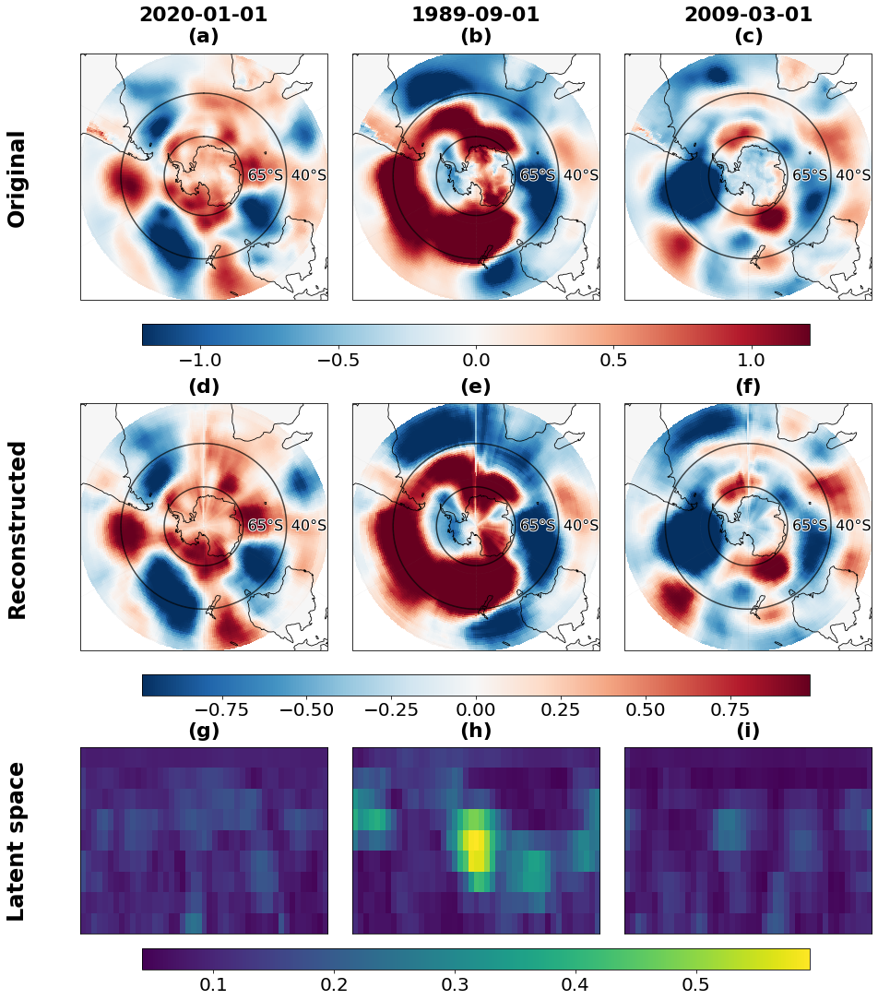

In [3]:
from tensorflow import keras

autoencoder = keras.models.load_model(f"{MODEL_DIR}/autoencoder_{TAG}.keras")

# three held-out months
RECON_MONTHS = ["2020-01", "1989-09", "2009-03"]
month = list(pd.to_datetime(times).strftime("%Y-%m"))
pick = [month.index(m) for m in RECON_MONTHS]
x_show = data_std[pick]
decoded = autoencoder.predict(x_show, verbose=0)
latent = encoded[pick].mean(axis=-1)

# vars to beautify
PLOT_STEP, FS = 4, 22
n_show = len(pick)
lats_plot, lons_plot = lats[::PLOT_STEP], lons[::PLOT_STEP]
pc = ccrs.PlateCarree()
theta = np.linspace(0, 2 * np.pi, 200)
letters = iter("abcdefghi")

fig = plt.figure(figsize=(4.2 * n_show + 0.8, 15), dpi=72)
gs = fig.add_gridspec(3, n_show, height_ratios=[1.6, 1.6, 1.0], hspace=0.2, wspace=0.1,
                      left=0.09, right=0.98, top=0.95, bottom=0.06)
rows = []
cbar_ref = None

# plot the original and reconstructed images
for row, imgs in enumerate([x_show, decoded]):
    flat = np.abs(imgs[:, ::PLOT_STEP, ::PLOT_STEP, 0])
    vmax = np.percentile(flat[np.isfinite(flat)], 90)
    norm = mcolors.Normalize(-vmax, vmax)
    cmap = plt.get_cmap("RdBu_r")
    axes = []
    for col in range(n_show):
        ax = fig.add_subplot(gs[row, col], projection=SPS)
        axes.append(ax)
        img = imgs[col, ::PLOT_STEP, ::PLOT_STEP, 0].astype(float)
        img_c, lon_c = add_cyclic_point(np.ma.masked_invalid(img), coord=lons_plot, axis=-1)
        ax.set_extent([-180, 180, -90, -20], pc)
        ax.pcolormesh(*np.meshgrid(lon_c, lats_plot), img_c, norm=norm, cmap=cmap, transform=pc,
                      shading="auto", linewidth=0, antialiased=False, edgecolors="face")
        ax.coastlines(linewidth=0.8, color="black")
        ax.add_feature(cfeature.LAND, facecolor="lightgray", alpha=0.2)
        for lat, lbl in [(-40., "40°S"), (-65., "65°S")]:
            ax.plot(np.degrees(theta), [lat] * 200, transform=pc, color="black", linewidth=1.5, alpha=0.7)
            ax.text(90., lat, f" {lbl}", transform=pc, ha="left", va="center", fontsize=FS - 6,
                    path_effects=[pe.withStroke(linewidth=2, foreground="white")])
        ax.gridlines(draw_labels=False, linewidth=0.5, color="gray", alpha=0.2, linestyle=":")
        # date on top line, letter on bottom line (row 0 only gets date)
        date = str(np.asarray(times[pick[col]], dtype="datetime64[D]"))
        ax.set_title(f"{date}\n({next(letters)})" if row == 0 else f"({next(letters)})",
                     fontsize=FS, fontweight="bold", pad=12)
    rows.append(axes)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes, orientation="horizontal",
                      fraction=0.07, pad=0.08, shrink=0.95, aspect=32)
    cb.ax.tick_params(labelsize=FS - 2)
    if row == 0:
        cbar_ref = cb

# latent row
lat_norm = mcolors.Normalize(latent.min(), latent.max())
axes = []
for col in range(n_show):
    ax = fig.add_subplot(gs[2, col])
    axes.append(ax)
    ax.imshow(latent[col], cmap="viridis", norm=lat_norm, aspect="auto", origin="upper")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"({next(letters)})", fontsize=FS, fontweight="bold", pad=12)
rows.append(axes)

# latent colorbar, same width as the map colorbars
fig.canvas.draw()
ref = cbar_ref.ax.get_position()
p0, p1 = axes[0].get_position(), axes[-1].get_position()
cax = fig.add_axes([p0.x0 + 0.5 * (p1.x1 - p0.x0 - ref.width),
                    min(ax.get_position().y0 for ax in axes) - 0.015 - ref.height, ref.width, ref.height])
fig.colorbar(plt.cm.ScalarMappable(norm=lat_norm, cmap="viridis"), cax=cax,
             orientation="horizontal").ax.tick_params(labelsize=FS - 2)

for axes, label in zip(rows, ["Original", "Reconstructed", "Latent space"]):
    p = axes[0].get_position()
    fig.text(0.02, p.y0 + p.height * 0.5, label, ha="center", va="center",
             fontsize=FS + 2, fontweight="bold", rotation=90)

save_figure(fig, "autoencoder_reconstruction")
del autoencoder, decoded

### Figures S4 and S14 -- Ward linkage-distance elbows for the CAE latent space and the PC scores

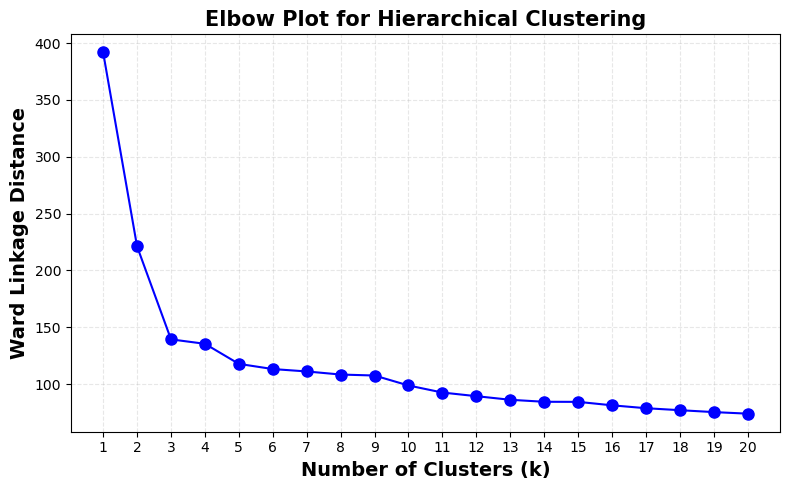

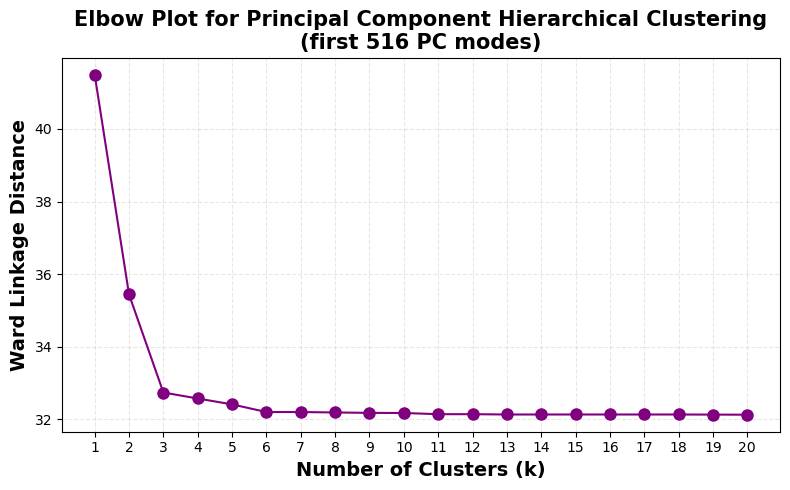

In [4]:
pcs_all = xr.open_dataset(PCA_ALL_FILE)["pcs"].values


def plot_elbow(Z, color, title, name):
    fig, ax = plt.subplots(figsize=(8, 5))
    elbow(ax, Z, color)
    ax.set_xlabel("Number of Clusters (k)", fontsize=14, fontweight="bold")
    ax.set_ylabel("Ward Linkage Distance", fontsize=14, fontweight="bold")
    ax.set_title(title, fontsize=15, fontweight="bold")
    fig.tight_layout()
    save_figure(fig, name)


plot_elbow(ward(encoded), "blue", "Elbow Plot for Hierarchical Clustering", "elbow")
plot_elbow(ward(pcs_all), "purple", "Elbow Plot for Principal Component Hierarchical Clustering\n"
           f"(first {pcs_all.shape[1]} PC modes)", "pca_elbow")

### Figure S13 -- composites from clustering all 516 PC scores

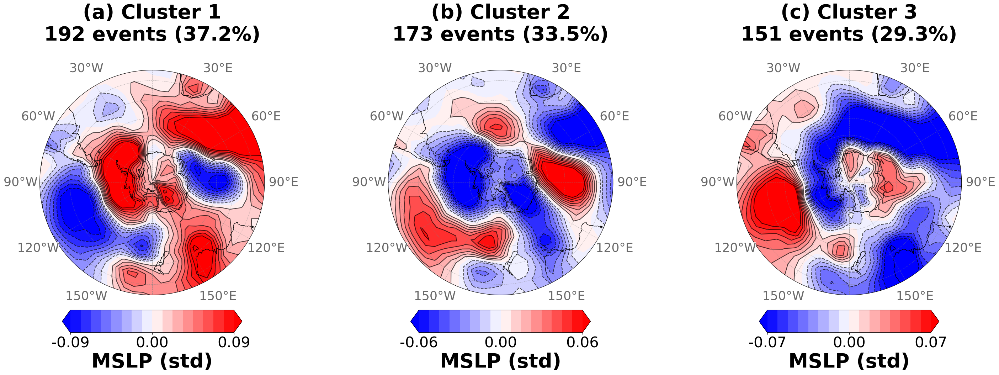

In [5]:
pca_labels = ward_labels(pcs_all, K)
lats_c, lons_c = lats[::20][:len(lats) // 20], lons[::20]

fig = plt.figure(figsize=(9 * K, 11))
for k in range(K):
    ax = fig.add_subplot(1, K, k + 1, projection=SPS)
    n = (pca_labels == k).sum()
    polar_map(ax, lons_c, lats_c, coarsen(data_std[pca_labels == k, :, :, 0].mean(axis=0), 20),
              title=f"({'abc'[k]}) Cluster {k + 1}\n{n} events ({100 * n / N:.1f}%)", label="MSLP (std)")
plt.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.11, wspace=0.55)
save_figure(fig, "pca_composites")

### Figure S6 -- the three composites on a common colour scale

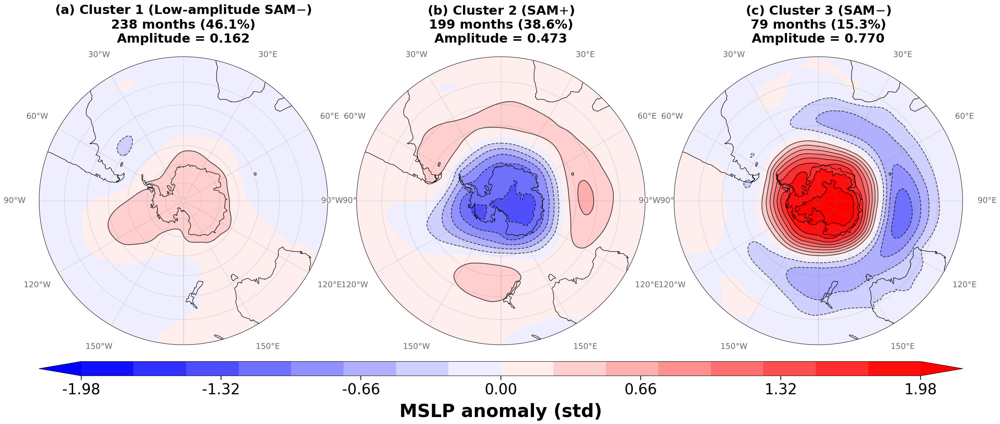

In [6]:
FS = fs_sizes(1.0)
VMAX = max(np.percentile(np.abs(c), PCT) for c in cae_composites)

fig = plt.figure(figsize=(27, 13))
axes = []
for k, c in enumerate(cae_composites):
    ax = fig.add_subplot(1, K, k + 1, projection=SPS)
    axes.append(ax)
    cf, _ = polar_map(ax, lons, lats, c, vmax=VMAX, add_colorbar=False, fs=0.62, title_pad=45,
                      title=(f"({'abc'[k]}) Cluster {k + 1} ({CLUSTER_NAMES[k]})\n"
                             f"{n_per_cluster[k]} months ({100 * n_per_cluster[k] / N:.1f}%)\n"
                             f"Amplitude = {amp_cae[k]:.3f}"))
plt.subplots_adjust(left=0.05, right=0.98, top=0.86, bottom=0.16, wspace=0.10)

# one colourbar across the row
boxes = [ax.get_position() for ax in axes]
x0, x1 = min(b.x0 for b in boxes), max(b.x1 for b in boxes)
cax = fig.add_axes([x0, min(b.y0 for b in boxes) - 0.065, x1 - x0, 0.030])
cbar = fig.colorbar(cf, cax=cax, orientation="horizontal")
ticks = np.linspace(-VMAX, VMAX, 7)
# odd tick counts leave a -2e-16 in the middle that %.2f prints as -0.00
cbar.set_ticks(ticks, labels=[f"{0.0 if abs(v) < 0.005 else v:.2f}" for v in ticks])
cbar.ax.tick_params(labelsize=FS["tick"] * 1.6, length=8, width=1.5, pad=6)
cbar.set_label("MSLP anomaly (std)", fontsize=FS["label"] * 1.6, fontweight="bold", labelpad=10)
save_figure(fig, "composites_common_colorbar")

### Figure S8 -- PC1 distributions within the three CAE classes

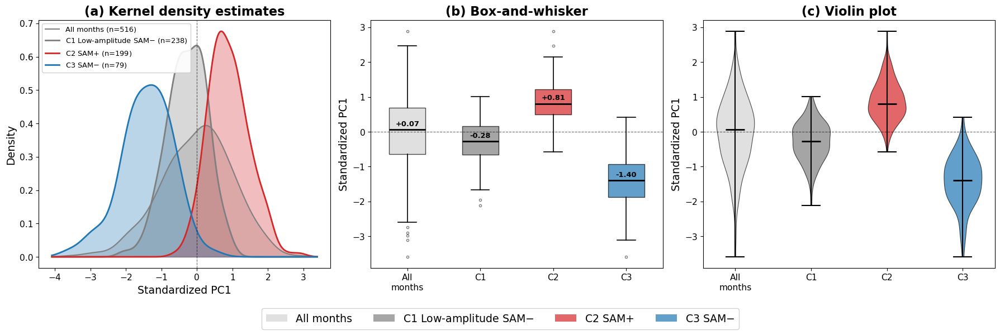

In [7]:
FS = fs_sizes(0.62)
COLORS = ["tab:gray", "tab:red", "tab:blue"]
samples = [pc1_std[labels == k] for k in range(K)]
box_data = [pc1_std] + samples
box_colors = ["lightgray"] + COLORS
box_labels = ["All\nmonths"] + [f"C{k + 1}" for k in range(K)]
x_grid = np.linspace(pc1_std.min() - 0.5, pc1_std.max() + 0.5, 500)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

ax = axes[0]
kde = gaussian_kde(pc1_std)(x_grid)
ax.fill_between(x_grid, kde, alpha=0.25, color="gray")
ax.plot(x_grid, kde, color="gray", lw=1.5, label=f"All months (n={N})")
for k in range(K):
    kde = gaussian_kde(samples[k])(x_grid)
    ax.fill_between(x_grid, kde, alpha=0.30, color=COLORS[k])
    ax.plot(x_grid, kde, color=COLORS[k], lw=2.0,
            label=f"C{k + 1} {CLUSTER_NAMES[k]} (n={len(samples[k])})")
ax.axvline(0, color="k", lw=0.8, ls="--", alpha=0.6)
ax.set_xlabel("Standardized PC1", fontsize=FS["label"])
ax.set_ylabel("Density", fontsize=FS["label"])
ax.set_title("(a) Kernel density estimates", fontsize=FS["title"], fontweight="bold")
ax.tick_params(labelsize=FS["tick"])
ax.legend(fontsize=FS["annot"], frameon=True, framealpha=0.9, loc="upper left")

ax = axes[1]
bp = ax.boxplot(box_data, patch_artist=True, widths=0.5, medianprops=dict(color="black", lw=2),
                whiskerprops=dict(lw=1.2), capprops=dict(lw=1.2),
                flierprops=dict(marker="o", markersize=3, alpha=0.5))
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for i, d in enumerate(box_data, start=1):
    ax.text(i, np.median(d) + 0.06, f"{np.median(d):+.2f}", ha="center", va="bottom",
            fontsize=FS["annot"], fontweight="bold")
ax.set_title("(b) Box-and-whisker", fontsize=FS["title"], fontweight="bold")

ax = axes[2]
vp = ax.violinplot(box_data, positions=range(1, 5), showmedians=True, showextrema=True)
for body, color in zip(vp["bodies"], box_colors):
    body.set_facecolor(color)
    body.set_alpha(0.7)
    body.set_edgecolor("black")
    body.set_linewidth(0.8)
for part in ("cmedians", "cmins", "cmaxes", "cbars"):
    vp[part].set_color("black")
vp["cmedians"].set_linewidth(2)
ax.set_xticks(range(1, 5))
ax.set_title("(c) Violin plot", fontsize=FS["title"], fontweight="bold")

for ax in axes[1:]:
    ax.set_xticklabels(box_labels, fontsize=FS["tick"])
    ax.set_ylabel("Standardized PC1", fontsize=FS["label"])
    ax.axhline(0, color="k", lw=0.8, ls="--", alpha=0.6)
    ax.tick_params(labelsize=FS["tick"])

handles = [Patch(facecolor="lightgray", alpha=0.7, label="All months")]
handles += [Patch(facecolor=c, alpha=0.7, label=f"C{k + 1} {n}")
            for k, (c, n) in enumerate(zip(COLORS, CLUSTER_NAMES))]
fig.legend(handles=handles, loc="lower center", ncol=4, fontsize=FS["label"],
           bbox_to_anchor=(0.5, -0.10), frameon=True, framealpha=0.9)
plt.tight_layout()
save_figure(fig, "pc1_distributions_by_cluster")

### Figures S9 and S10 -- occupancy-matched PC1 composites against the CAE composites

Rank the months by PC1 and cut them into groups the size of the three CAE classes: the most negative PC1 months pair with Cluster 3, the most positive with Cluster 2 and the middle with Cluster 1.

In [8]:
PC1_GROUP_NAMES = ["Near-zero PC1", "Most positive PC1", "Most negative PC1"]
order = np.argsort(pc1)
_, n2, n3 = n_per_cluster
groups = [order[n3:N - n2], order[-n2:], order[:n3]]

pc1_composites = [data_phys[g].mean(axis=0).astype(np.float64) for g in groups]
amp_pc1 = [area_weighted_rms(c, lats) for c in pc1_composites]
eta_pc1 = [non_annularity(c, cos_lat) for c in pc1_composites]
eta_cae = [non_annularity(c, cos_lat) for c in cae_composites]

print(f"{'':<36}{'r':>7}{'eta PC1':>9}{'eta CAE':>9}")
for k in range(K):
    r = spatial_corr(pc1_composites[k], cae_composites[k], cos_lat[:, None])
    print(f"{PC1_GROUP_NAMES[k] + ' vs C' + str(k + 1):<36}{r:>7.3f}{eta_pc1[k]:>9.3f}{eta_cae[k]:>9.3f}")
print(f"eta(C1) / eta(C3): CAE {eta_cae[0] / eta_cae[2]:.1f}, PC1 groups {eta_pc1[0] / eta_pc1[2]:.1f}")

                                          r  eta PC1  eta CAE
Near-zero PC1 vs C1                   0.928    0.147    0.280
Most positive PC1 vs C2               0.987    0.094    0.064
Most negative PC1 vs C3               0.951    0.092    0.060
eta(C1) / eta(C3): CAE 4.6, PC1 groups 1.6


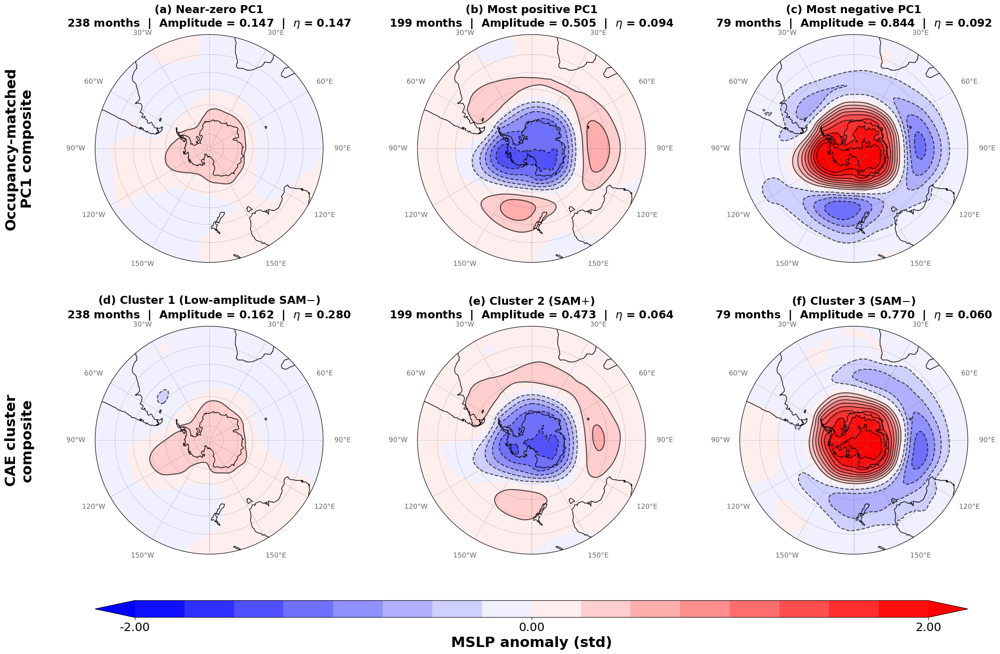

In [9]:
FS = fs_sizes(1.0)
rows = [pc1_composites, cae_composites]
VMAX = max(np.percentile(np.abs(c), PCT) for row in rows for c in row)

fig = plt.figure(figsize=(22, 15))
axes = []
for row, (comps, amps, etas) in enumerate([(pc1_composites, amp_pc1, eta_pc1),
                                           (cae_composites, amp_cae, eta_cae)]):
    for k in range(K):
        ax = fig.add_subplot(2, K, row * K + k + 1, projection=SPS)
        axes.append(ax)
        name = PC1_GROUP_NAMES[k] if row == 0 else f"Cluster {k + 1} ({CLUSTER_NAMES[k]})"
        cf, _ = polar_map(ax, lons, lats, comps[k], vmax=VMAX, add_colorbar=False, fs=0.42, title_pad=30,
                          title=(f"({'abcdef'[row * K + k]}) {name}\n{n_per_cluster[k]} months  |  "
                                 f"Amplitude = {amps[k]:.3f}  |  $\\eta$ = {etas[k]:.3f}"))
plt.subplots_adjust(left=0.07, right=0.98, top=0.90, bottom=0.16, wspace=0.10, hspace=0.28)

for row, label in enumerate(["Occupancy-matched\nPC1 composite", "CAE cluster\ncomposite"]):
    boxes = [ax.get_position() for ax in axes[row * K:(row + 1) * K]]
    fig.text(0.028, 0.5 * (min(b.y0 for b in boxes) + max(b.y1 for b in boxes)), label,
             rotation=90, ha="center", va="center", fontsize=FS["label"], fontweight="bold")

boxes = [ax.get_position() for ax in axes]
x0, x1 = min(b.x0 for b in boxes), max(b.x1 for b in boxes)
cbar = fig.colorbar(cf, cax=fig.add_axes([x0, 0.070, x1 - x0, 0.024]), orientation="horizontal")
cbar.set_ticks(np.linspace(-VMAX, VMAX, 3))
cbar.ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
cbar.ax.tick_params(labelsize=FS["tick"])
cbar.set_label("MSLP anomaly (std)", fontsize=FS["label"], fontweight="bold")
save_figure(fig, "occupancy_matched_composites")

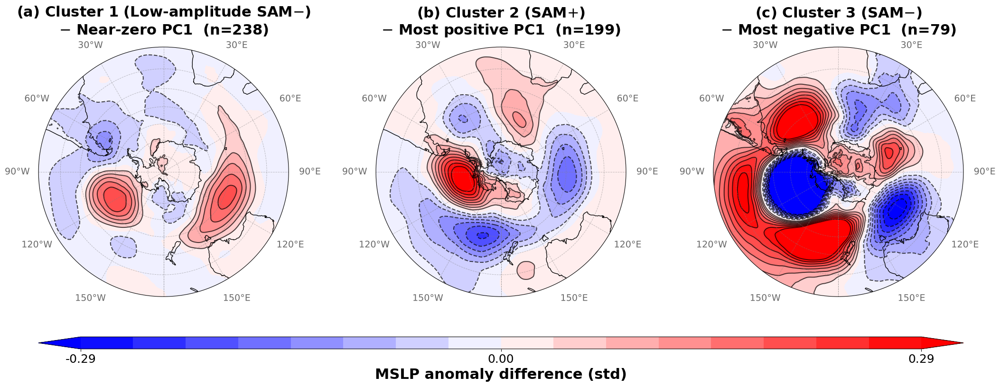

In [10]:
diffs = [cae_composites[k] - pc1_composites[k] for k in range(K)]
VMAX = max(np.percentile(np.abs(d), PCT) for d in diffs)

fig = plt.figure(figsize=(22, 8.5))
axes = []
for k, d in enumerate(diffs):
    ax = fig.add_subplot(1, K, k + 1, projection=SPS)
    axes.append(ax)
    cf, _ = polar_map(ax, lons, lats, d, vmax=VMAX, add_colorbar=False, fs=0.55, title_pad=35,
                      title=(f"({'abc'[k]}) Cluster {k + 1} ({CLUSTER_NAMES[k]})\n"
                             f"$-$ {PC1_GROUP_NAMES[k]}  (n={n_per_cluster[k]})"))
plt.subplots_adjust(left=0.04, right=0.98, top=0.84, bottom=0.22, wspace=0.10)

boxes = [ax.get_position() for ax in axes]
x0, x1 = min(b.x0 for b in boxes), max(b.x1 for b in boxes)
cbar = fig.colorbar(cf, cax=fig.add_axes([x0, 0.090, x1 - x0, 0.030]), orientation="horizontal")
cbar.set_ticks(np.linspace(-VMAX, VMAX, 3))
cbar.ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
cbar.ax.tick_params(labelsize=FS["tick"])
cbar.set_label("MSLP anomaly difference (std)", fontsize=FS["label"], fontweight="bold")
save_figure(fig, "occupancy_matched_difference_maps")

### Figure S15 -- shuffled-label null test for the transition matrix

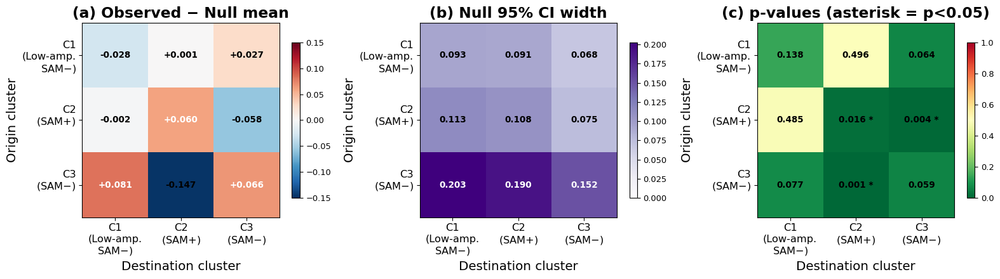

In [11]:
FS = fs_sizes(0.65)
obs = transition_matrix(labels)
null = shuffle_null(labels, np.random.default_rng(RNG_SEED), N_SHUFFLE)
p = p_values(obs, null)
ci_width = np.percentile(null, 97.5, axis=0) - np.percentile(null, 2.5, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
heatmap(axes[0], obs - null.mean(axis=0), "(a) Observed − Null mean", "RdBu_r", -0.15, 0.15, TICKS, FS, fmt="+.3f")
heatmap(axes[1], ci_width, "(b) Null 95% CI width", "Purples", 0, ci_width.max(), TICKS, FS)
heatmap(axes[2], p, "(c) p-values (asterisk = p<0.05)", "RdYlGn_r", 0, 1, TICKS, FS,
        stars=p < 0.05, text_color=lambda v: "black")
plt.tight_layout()
save_figure(fig, "shuffled_null_test")

### Figure S16 -- the same transition statistics for the PC1-rank groups

PC1 is persistent month to month, so ranking by PC1 alone might already give persistent extreme groups with few direct jumps between them.

R_ij = P(j|i) / P(j):
 [[1.03 0.88 1.21]
 [0.9  1.34 0.46]
 [1.15 0.53 1.74]]
p-values:
 [[0.291 0.029 0.048]
 [0.041 0.    0.   ]
 [0.096 0.    0.002]]


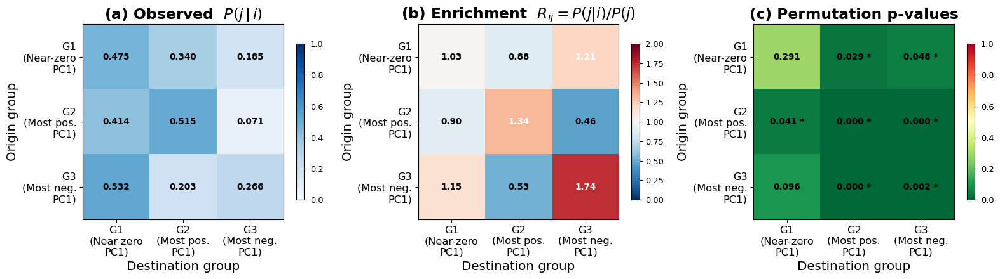

In [12]:
pc1_labels = np.empty(N, dtype=int)
for g, idx in enumerate(groups):
    pc1_labels[idx] = g

obs = transition_matrix(pc1_labels)
ratio = obs / (np.bincount(pc1_labels) / N)[None, :]
null = shuffle_null(pc1_labels, np.random.default_rng(RNG_SEED), N_SHUFFLE)
p = p_values(obs, null)
print("R_ij = P(j|i) / P(j):\n", ratio.round(2))
print("p-values:\n", p.round(3))

ticks = ["G1\n(Near-zero\nPC1)", "G2\n(Most pos.\nPC1)", "G3\n(Most neg.\nPC1)"]
kw = dict(ticks=ticks, fs=FS, xlabel="Destination group", ylabel="Origin group")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
heatmap(axes[0], obs, "(a) Observed  $P(j\\,|\\,i)$", "Blues", 0, 1, **kw)
heatmap(axes[1], ratio, "(b) Enrichment  $R_{ij}=P(j|i)/P(j)$", "RdBu_r", 0, 2, fmt=".2f", **kw)
heatmap(axes[2], p, "(c) Permutation p-values", "RdYlGn_r", 0, 1, stars=p < 0.05, **kw)
plt.tight_layout()
save_figure(fig, "pc1_group_transitions")

### Figure S18 -- transition statistics within each season

Only transitions with both months in the season count, and the null shuffles labels within the season.

In [13]:
SEASON_MONTHS = {"DJF": (12, 1, 2), "MAM": (3, 4, 5), "JJA": (6, 7, 8), "SON": (9, 10, 11)}
season_of = pd.to_datetime(times).month.map({m: s for s, ms in SEASON_MONTHS.items() for m in ms}).values
rng = np.random.default_rng(RNG_SEED)

season_trans = {}
for s in SEASON_MONTHS:
    pairs = (season_of[:-1] == s) & (season_of[1:] == s)
    idx = np.where(season_of == s)[0]
    obs = transition_matrix(labels, pairs=pairs)
    null = []
    for _ in range(N_SHUFFLE):
        shuffled = labels.copy()
        shuffled[idx] = labels[idx[rng.permutation(len(idx))]]
        null.append(transition_matrix(shuffled, pairs=pairs))
    p = p_values(obs, np.array(null))
    occ = np.bincount(labels[idx], minlength=K) / len(idx)
    season_trans[s] = dict(obs=obs, delta=obs - occ[None, :], p=p, n_trans=int(pairs.sum()), n_months=len(idx))
    for i, j in zip(*np.where((p < 0.05) & ~np.eye(K, dtype=bool))):
        print(f"{s}  C{i + 1} -> C{j + 1}  P={obs[i, j]:.3f}  dP={obs[i, j] - occ[j]:+.3f}  p={p[i, j]:.3f}")

DJF  C3 -> C1  P=0.733  dP=+0.307  p=0.011


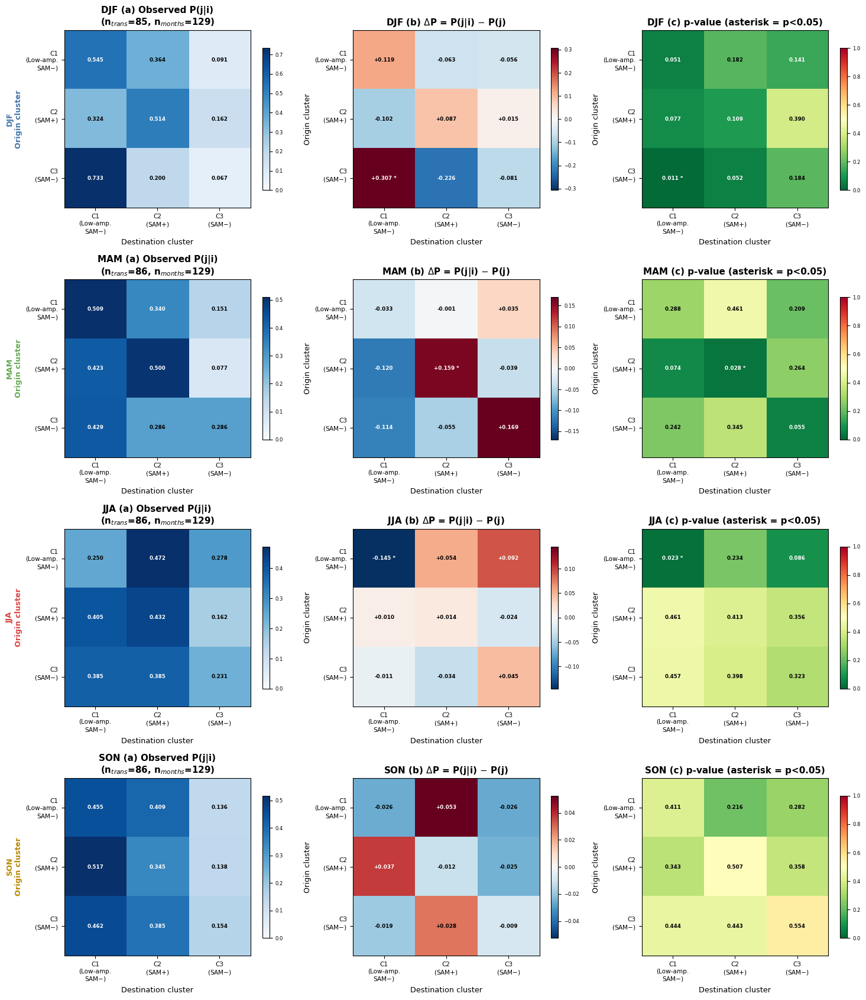

In [14]:
FS = fs_sizes(0.42)
SEASON_COLORS = {"DJF": "#4477AA", "MAM": "#66AA55", "JJA": "#DD4444", "SON": "#BB8800"}

fig, axes = plt.subplots(4, 3, figsize=(15, 17))
for row, (s, d) in enumerate(season_trans.items()):
    vmax = d["obs"].max()
    heatmap(axes[row, 0], d["obs"], f"{s} (a) Observed P(j|i)\n"
            f"(n$_{{trans}}$={d['n_trans']}, n$_{{months}}$={d['n_months']})", "Blues", 0.0, vmax,
            TICKS, FS, text_color=luminance_color("Blues", 0.0, vmax))
    vmax = np.abs(d["delta"]).max()
    heatmap(axes[row, 1], d["delta"], f"{s} (b) $\\Delta$P = P(j|i) $-$ P(j)", "RdBu_r", -vmax, vmax,
            TICKS, FS, fmt="+.3f", stars=d["p"] < 0.05, text_color=luminance_color("RdBu_r", -vmax, vmax))
    heatmap(axes[row, 2], d["p"], f"{s} (c) p-value (asterisk = p<0.05)", "RdYlGn_r", 0, 1,
            TICKS, FS, stars=d["p"] < 0.05, text_color=luminance_color("RdYlGn_r", 0, 1))
    axes[row, 0].set_ylabel(f"{s}\nOrigin cluster", fontsize=FS["label"], fontweight="bold",
                            color=SEASON_COLORS[s])
plt.tight_layout()
save_figure(fig, "seasonal_transition_heatmaps")

del data_std, data_phys, encoded

## 2. The four per-season CAE runs

Climatology and trend are removed within each season before training (`train_autoencoder.py --season`).

In [15]:
N_CLUSTERS_PER_SEASON = {"DJF": 4, "MAM": 4, "JJA": 3, "SON": 3}   # from the elbows in Fig S17
AVG_COARSEN = 20

seasons = {}
for s, k in N_CLUSTERS_PER_SEASON.items():
    tag = f"{TAG}_lintrend_{s}"
    encoded, data_std = load("encoded_all", tag), load("data_standardized", tag)
    lab = ward_labels(encoded, k)
    # composite on the coarse grid, then divide by the coarsened training weight
    w = load("lat_weights", tag)
    w = w[:len(w) // AVG_COARSEN * AVG_COARSEN].reshape(-1, AVG_COARSEN).mean(axis=1)[:, None]
    imgs = np.array([coarsen(x[..., 0], AVG_COARSEN) for x in data_std])
    X = imgs.reshape(len(imgs), -1).astype(np.float64)
    eof1 = np.linalg.svd(X - X.mean(axis=0), full_matrices=False)[2][0].reshape(imgs[0].shape)
    eof1 /= np.abs(eof1).max()
    seasons[s] = dict(
        Z=ward(encoded), n=len(lab), sizes=np.bincount(lab),
        composites=[imgs[lab == c].mean(axis=0) / w for c in range(k)],
        eof1=eof1 if eof1.mean() >= 0 else -eof1,
    )
del encoded, data_std, imgs, X

### Figure S17 -- per-season elbows

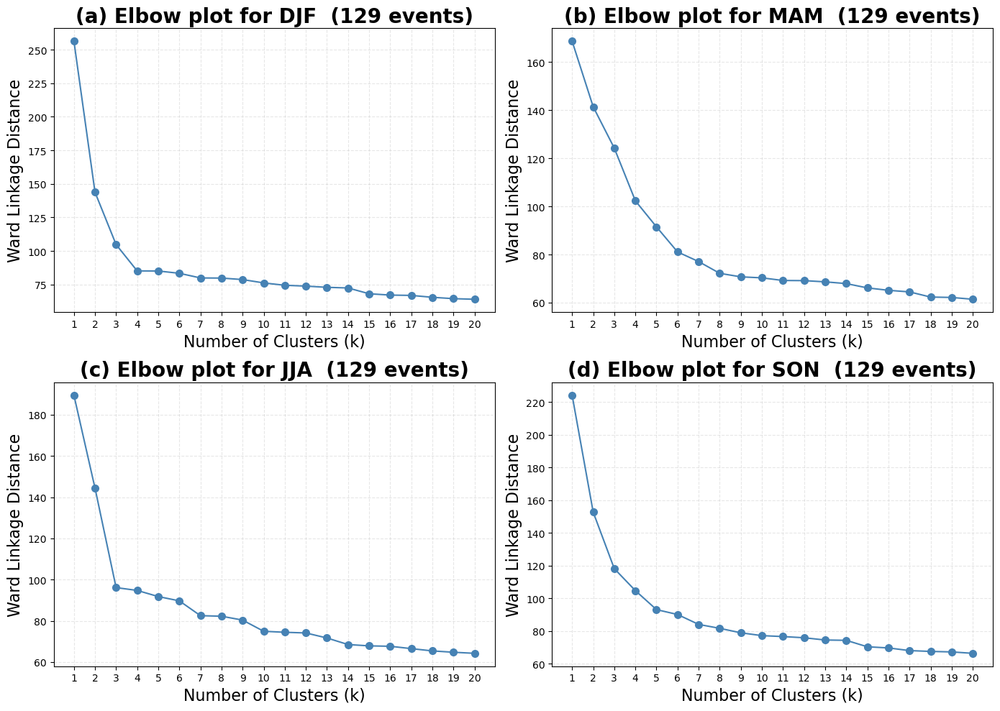

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (s, d), letter in zip(axes.flat, seasons.items(), "abcd"):
    elbow(ax, d["Z"], "steelblue", ms=7)
    ax.set_title(f"({letter}) Elbow plot for {s}  ({d['n']} events)", fontsize=20, fontweight="bold")
    ax.set_xlabel("Number of Clusters (k)", fontsize=16)
    ax.set_ylabel("Ward Linkage Distance", fontsize=16)
fig.tight_layout()
save_figure(fig, "season_linkages")

### Figure 8 -- seasonal EOF1 and CAE composites

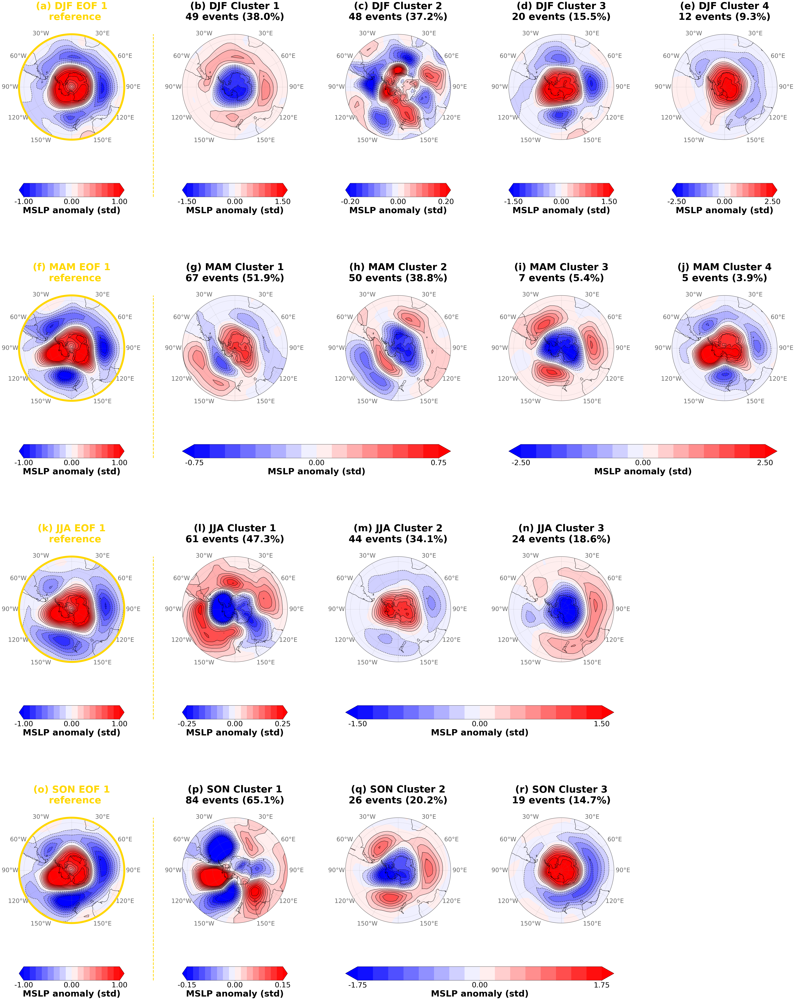

In [17]:
# colour limits per cluster, and which clusters share a colourbar
SEASON_VMAX = {"DJF": [1.5, 0.2, 1.5, 2.5], "MAM": [0.75, 0.75, 2.5, 2.5],
               "JJA": [0.25, 1.5, 1.5], "SON": [0.15, 1.75, 1.75]}
SEASON_CBARS = {"DJF": [[0], [1], [2], [3]], "MAM": [[0, 1], [2, 3]],
                "JJA": [[0], [1, 2]], "SON": [[0], [1, 2]]}
GOLD = "gold"
lats_c, lons_c = lats[::AVG_COARSEN][:len(lats) // AVG_COARSEN], lons[::AVG_COARSEN]
letters = iter("abcdefghijklmnopqrstuvwxyz")


def style_cbar(cb, vmax):
    cb.set_ticks(np.linspace(-vmax, vmax, 3))
    cb.ax.xaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
    cb.ax.tick_params(labelsize=30)
    cb.set_label("MSLP anomaly (std)", fontsize=36, fontweight="bold")


# map row, colorbar row, spacer row between seasons
fig = plt.figure(figsize=(9.0 * 5 + 1.5, 15 * 4))
gs = GridSpec(11, 5, figure=fig, height_ratios=[14, 1, 4] * 3 + [14, 1], hspace=0.00, wspace=0.55,
              left=0.04, right=0.98, top=0.98, bottom=0.03)

for i, (s, d) in enumerate(seasons.items()):
    row = 3 * i
    ax_eof = fig.add_subplot(gs[row, 0], projection=SPS)
    cf, _ = polar_map(ax_eof, lons_c, lats_c, d["eof1"], add_colorbar=False,
                      title=f"({next(letters)}) {s} EOF 1\n  reference")
    ax_eof.title.set_color(GOLD)
    ax_eof.spines["geo"].set_linewidth(8)
    ax_eof.spines["geo"].set_edgecolor(GOLD)
    cax_eof = fig.add_subplot(gs[row + 1, 0])
    style_cbar(fig.colorbar(cf, cax=cax_eof, orientation="horizontal"), 1)

    cfs, cluster_axes = [], []
    for c, comp in enumerate(d["composites"]):
        ax = fig.add_subplot(gs[row, 1 + c], projection=SPS)
        cluster_axes.append(ax)
        cf, _ = polar_map(ax, lons_c, lats_c, comp, vmax=SEASON_VMAX[s][c], add_colorbar=False,
                          title=(f"({next(letters)}) {s} Cluster {c + 1}\n"
                                 f"{d['sizes'][c]} events ({100 * d['sizes'][c] / d['n']:.1f}%)"))
        cfs.append(cf)
    for g in SEASON_CBARS[s]:
        cax = fig.add_subplot(gs[row + 1, 1 + g[0]:2 + g[-1]])
        style_cbar(fig.colorbar(cfs[g[0]], cax=cax, orientation="horizontal"), SEASON_VMAX[s][g[0]])

    # gold separator across this season's row
    fig.canvas.draw()
    x = (ax_eof.get_position().x1 + cluster_axes[0].get_position().x0) / 2
    fig.add_artist(Line2D([x, x], [cax_eof.get_position().y0, ax_eof.get_position().y1],
                          transform=fig.transFigure, color=GOLD, linewidth=3, linestyle="--",
                          clip_on=False, zorder=10))

save_figure(fig, "all_seasons_clusters")

## 3. The ten-member initialisation ensemble

Cluster each member's latent space with Ward linkage at k = 3 > pick the reference member as the **ensemble medoid** > order the reference clusters by SAM index > match every member to it by Hungarian assignment on area-weighted spatial correlation.

All members were trained on the same input, so one de-weighted field serves all ten.

In [18]:
data_phys = undo_lat_weight(load("data_standardized", SEED_TAG.format(0), SEED_DIR), lats)
cos_w = cos_lat[:, None]

members = {}
for s in SEEDS:
    lab = ward_labels(load("encoded_all", SEED_TAG.format(s), SEED_DIR), K)
    members[s] = dict(labels=lab, composites=[data_phys[lab == k].mean(axis=0) for k in range(K)])

# reference = the member closest to all the others
score = {}
for cand in SEEDS:
    r = []
    for s in SEEDS:
        if s != cand:
            perm, corr = match_clusters(members[s]["composites"], members[cand]["composites"], cos_w)
            r.extend(corr[range(K), perm])
    score[cand] = np.mean(r)
REF_SEED = max(score, key=score.get)
ref_composites = [members[REF_SEED]["composites"][o] for o in physical_order(members[REF_SEED]["composites"], lats)]
print(f"reference seed {REF_SEED} (mean matched r = {score[REF_SEED]:.3f})")

for s, m in members.items():
    perm, corr = match_clusters(m["composites"], ref_composites, cos_w)
    m["composites"] = [m["composites"][p] for p in perm]
    m["labels"] = np.argsort(perm)[m["labels"]]
    m["r_ref"] = corr[range(K), perm]

occupancy = np.array([100 * np.bincount(members[s]["labels"], minlength=K) / N for s in SEEDS])
ens_mean = np.mean([members[s]["composites"] for s in SEEDS], axis=0)

r_ref = np.array([members[s]["r_ref"] for s in SEEDS if s != REF_SEED])
for k in range(K):
    print(f"Cluster {k + 1}: occupancy {occupancy[:, k].mean():.1f} +/- {occupancy[:, k].std(ddof=1):.1f}%, "
          f"r_ref {r_ref[:, k].min():+.2f} to {r_ref[:, k].max():+.2f}")

reference seed 3 (mean matched r = 0.892)


Cluster 1: occupancy 44.2 +/- 6.8%, r_ref -0.92 to +0.98
Cluster 2: occupancy 39.7 +/- 13.3%, r_ref +0.97 to +1.00
Cluster 3: occupancy 16.1 +/- 11.8%, r_ref +0.95 to +0.99


### Figure 2 -- ensemble-mean composites with consensus stippling

A grid point is stippled where the composite's 90% bootstrap interval excludes zero in at least 7 of the 10 members.

significant in >= 7/10 seeds: ['54%', '75%', '77%']


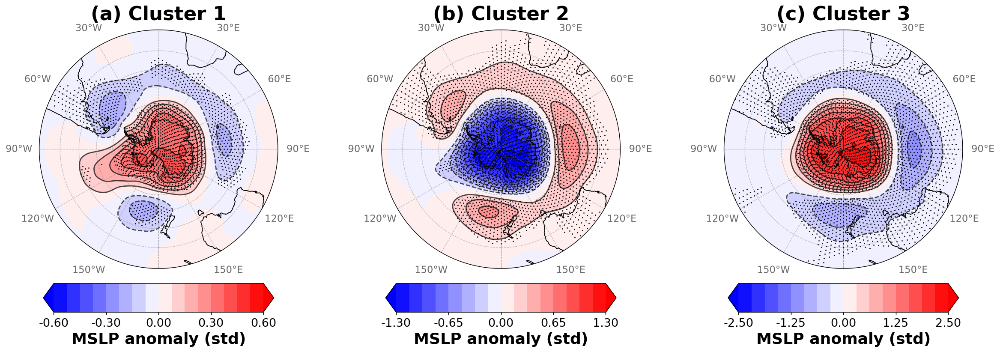

In [19]:
N_BOOT_SIG, MIN_SEEDS, BAND = 200, 7, 100
rng = np.random.default_rng(RNG_SEED)
sig = np.zeros((len(SEEDS), K) + data_phys.shape[1:], dtype=bool)
for i, s in enumerate(SEEDS):
    for k in range(K):
        idx = np.where(members[s]["labels"] == k)[0]
        draws = rng.integers(0, len(idx), size=(N_BOOT_SIG, len(idx)))
        # latitude bands keep the bootstrap array small
        for b0 in range(0, len(lats), BAND):
            band = data_phys[idx, b0:b0 + BAND]
            boot = np.array([band[d].mean(axis=0) for d in draws])
            lo, hi = np.percentile(boot, [5, 95], axis=0)
            sig[i, k, b0:b0 + BAND] = (lo > 0) | (hi < 0)
consensus = sig.sum(axis=0) >= MIN_SEEDS
print("significant in >= 7/10 seeds:", [f"{100 * c.mean():.0f}%" for c in consensus])

fig, axes = plt.subplots(1, K, figsize=(K * 6.2, 6.4), dpi=130, subplot_kw={"projection": SPS})
for k, ax in enumerate(axes):
    polar_map(ax, lons, lats, ens_mean[k], title=f"({'abc'[k]}) Cluster {k + 1}", vmax=[0.6, 1.3, 2.5][k],
              edge_lat=-20, pole_fix=True, fs=0.5, title_pad=26, cbar_nticks=5)
    ax.title.set_fontsize(25)
    stipple(ax, lons, lats, consensus[k], stride=(4, 20), size=10.0)
plt.tight_layout()
save_figure(fig, "ensemble_composite")

### Figure 3 -- occupancy across the ten initialisations

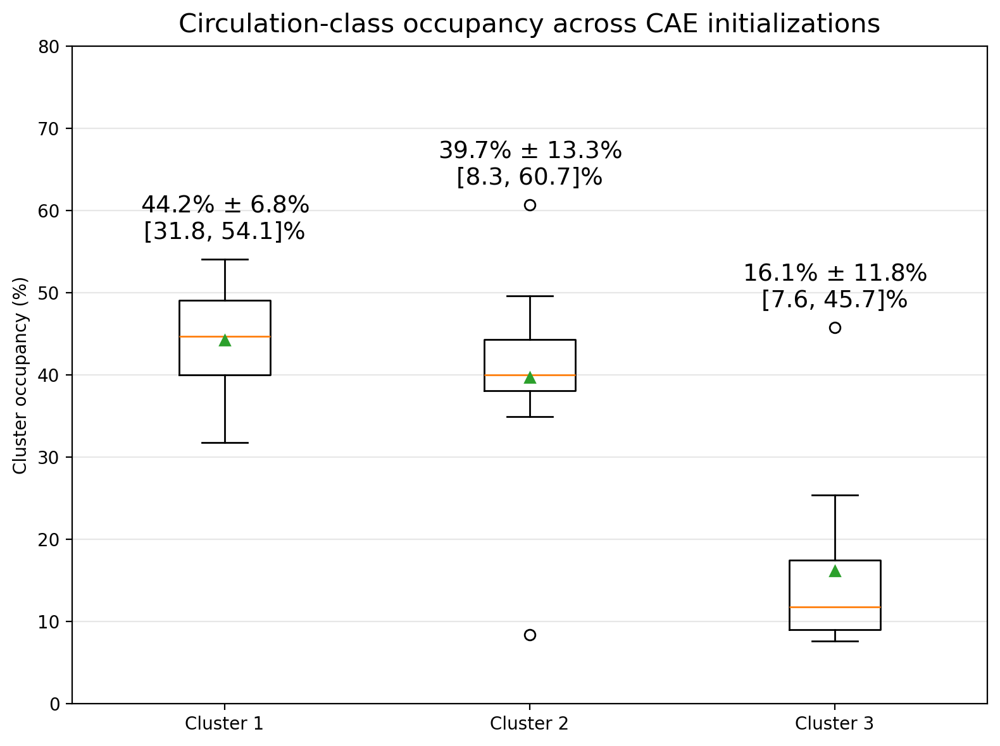

In [20]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=200)
ax.boxplot([occupancy[:, k] for k in range(K)], showmeans=True)
for k in range(K):
    v = occupancy[:, k]
    ax.annotate(f"{v.mean():.1f}% $\\pm$ {v.std(ddof=1):.1f}%\n[{v.min():.1f}, {v.max():.1f}]%",
                xy=(k + 1, v.max()), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=FS_TICK * 0.75)
ax.set_xticks(range(1, K + 1))
ax.set_xticklabels([f"Cluster {k + 1}" for k in range(K)], ha="center")
ax.set_ylabel("Cluster occupancy (%)")
ax.set_ylim(0, 80)
ax.grid(axis="y", alpha=0.3)
ax.set_title("Circulation-class occupancy across CAE initializations", fontsize=15, pad=8)
plt.tight_layout()
save_figure(fig, "occupancy_box")

### Figure 4 -- temporal evolution of the three regimes

Project every month onto each member's composites (polar rows dropped), standardize, flip the sign to match EOF1, then average over the ten members.

In [21]:
def standardize(x):
    return (x - x.mean()) / (x.std() + 1e-12)


# 10-yr running mean, in months at the 31-day spacing of the first two time steps
WIN = int(365.25 * 10 / 31)


def running(x):
    return pd.Series(x).rolling(WIN, center=True, min_periods=WIN // 3).mean().values


eof1 = eofs[0].astype(np.float64)
pole = np.abs(lats) > 89.0
B = data_phys.reshape(N, -1).astype(np.float64)
proj = np.zeros((len(SEEDS), K, N))
for i, s in enumerate(SEEDS):
    for k, c in enumerate(members[s]["composites"]):
        pattern = c.astype(np.float64)
        pattern[pole] = 0.0
        sign = 1 if spatial_corr(c.astype(np.float64), eof1, cos_w) >= 0 else -1
        proj[i, k] = sign * standardize(B @ pattern.ravel())
del B
proj_mean = proj.mean(axis=0)
pc_z = standardize(pc1)

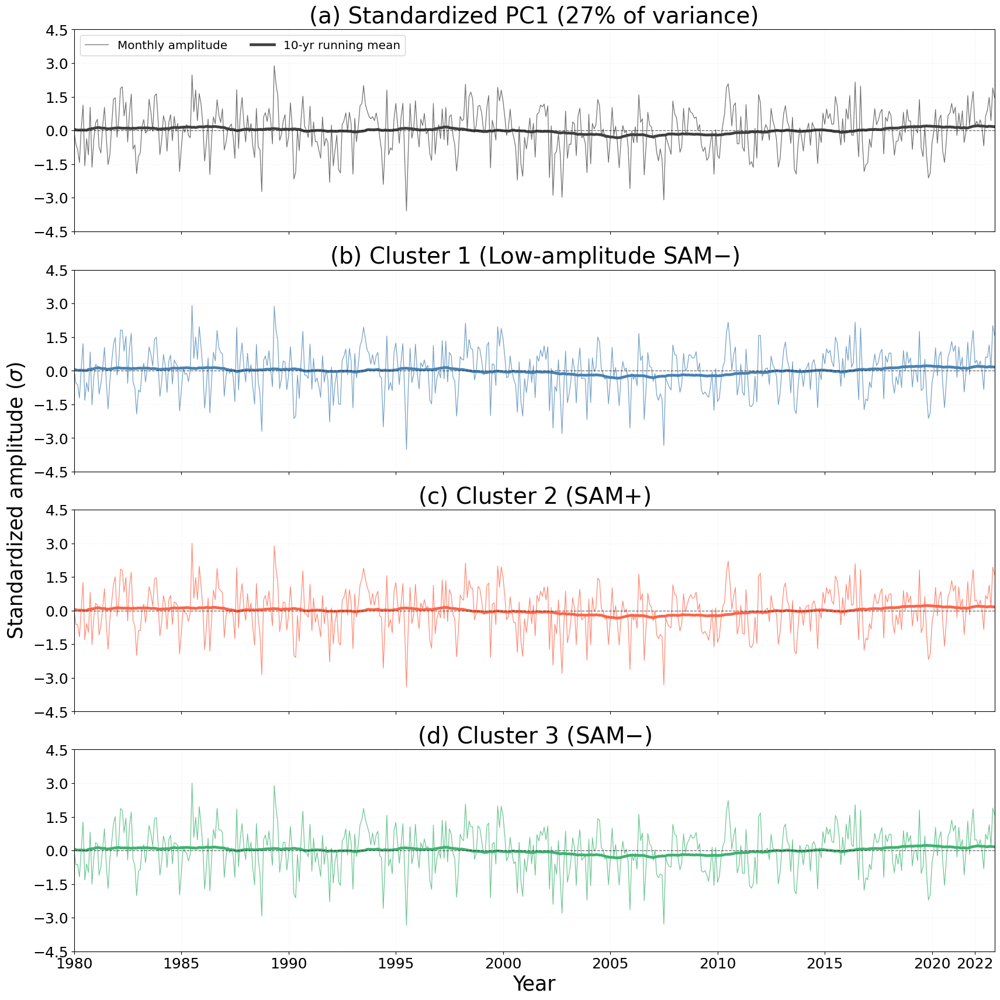

In [22]:
time_index = pd.DatetimeIndex(times)
panels = [(f"Standardized PC1 ({var_ex[0]:.0%} of variance)", pc_z, running(pc_z), "0.25")]
panels += [(f"Cluster {k + 1} ({CLUSTER_NAMES[k]})", proj_mean[k],
            np.mean([running(p) for p in proj[:, k]], axis=0), c)
           for k, c in enumerate(["steelblue", "tomato", "mediumseagreen"])]

# symmetric y-limits with ticks on the limits, at the coarsest step giving <= 7 ticks
vmax = max(np.abs(m).max() for _, m, _, _ in panels)
for step in (0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 5.0):
    ylim = np.ceil(vmax / step) * step
    if 2 * ylim / step + 1 <= 7:
        break

fig, axes = plt.subplots(len(panels), 1, figsize=(17, 17), sharex=True, sharey=True, constrained_layout=True)
for ax, letter, (label, monthly, smooth, color) in zip(axes, "abcd", panels):
    ax.plot(time_index, monthly, color=color, lw=0.9, alpha=0.75, label="Monthly amplitude")
    ax.plot(time_index, smooth, color=color, lw=3.4, label="10-yr running mean")
    ax.axhline(0, color="black", ls="--", lw=0.9, alpha=0.6)
    ax.set_title(f"({letter}) {label}", fontsize=28, pad=8)
    ax.grid(alpha=0.22, linestyle=":")
    ax.tick_params(labelsize=18)
axes[0].legend(fontsize=fs_sizes(0.8)["tick"], loc="upper left", ncol=2, framealpha=0.85)
axes[0].set_ylim(-ylim, ylim)
axes[0].set_yticks(np.arange(-ylim, ylim + 0.5 * step, step))
axes[0].set_xlim(time_index[0], time_index[-1])
axes[0].set_xticks(pd.to_datetime([f"{y}-01-01" for y in [*range(1980, 2021, 5), time_index[-1].year]]))
axes[0].xaxis.set_major_formatter(DateFormatter("%Y"))
fig.supylabel(r"Standardized amplitude ($\sigma$)", fontsize=25)
axes[-1].set_xlabel("Year", fontsize=25)
save_figure(fig, "temporal_proj")

### Figure 5 -- the 516 months in PC1-PC2 space

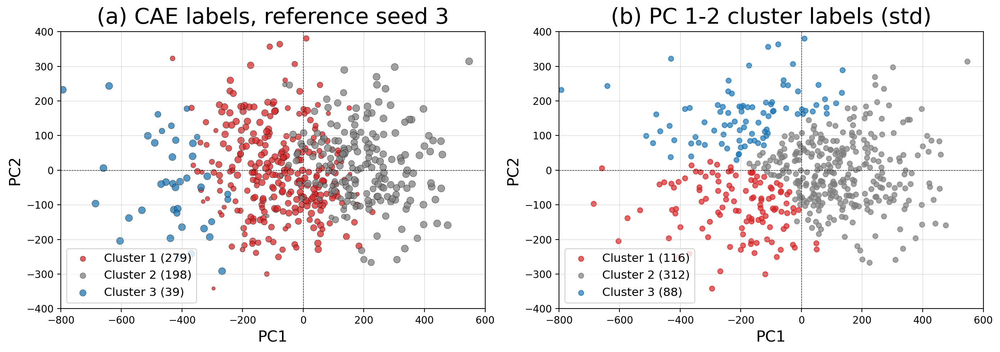

In [23]:
ref_labels = members[REF_SEED]["labels"]
agreement = np.mean([members[s]["labels"] == ref_labels for s in SEEDS], axis=0)

# Ward clusters of the standardized PC1-PC2 scores, relabelled to best match the CAE labels
pc_labels = ward_labels(pcs[:, :2], K)
overlap = np.array([[np.sum((pc_labels == a) & (ref_labels == b)) for b in range(K)] for a in range(K)])
pc_labels = linear_sum_assignment(-overlap)[1][pc_labels]

colors = ["tab:red", "tab:gray", "tab:blue"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=200)
for k in range(K):
    m = ref_labels == k
    axes[0].scatter(pcs[m, 0], pcs[m, 1], c=colors[k], s=8 + 42 * agreement[m], alpha=0.75,
                    edgecolor="black", linewidth=0.3, label=f"Cluster {k + 1} ({m.sum()})")
    m = pc_labels == k
    axes[1].scatter(pcs[m, 0], pcs[m, 1], c=colors[k], s=25, alpha=0.7, label=f"Cluster {k + 1} ({m.sum()})")
for ax, title in zip(axes, [f"(a) CAE labels, reference seed {REF_SEED}", "(b) PC 1-2 cluster labels (std)"]):
    ax.set_xlabel("PC1", fontsize=FS_LABEL * 0.7)
    ax.set_ylabel("PC2", fontsize=FS_LABEL * 0.7)
    ax.set_title(title, fontsize=FS_LABEL, pad=8)
    ax.legend(fontsize=FS_TICK * 0.65, loc="lower left")
    ax.set_xlim(-800, 600)
    ax.set_ylim(-400, 400)
    ax.grid(lw=0.25, zorder=-1)
    ax.axhline(0, color="k", lw=0.5, ls="--")
    ax.axvline(0, color="k", lw=0.5, ls="--")
plt.tight_layout()
save_figure(fig, "scatter")

### Figure 6 -- non-annularity of EOF1 and the ensemble-mean composites

Clusters: bootstrap the months within each class of each member. EOF1: a fixed pattern has nothing to resample, so bootstrap the PC1-weighted composite instead, its closest analogue of a class composite.

In [24]:
N_BOOT_ETA = 300
rng = np.random.default_rng(RNG_SEED)
eta_boot = np.zeros((len(SEEDS), K, N_BOOT_ETA))
for i, s in enumerate(SEEDS):
    for k in range(K):
        idx = np.where(members[s]["labels"] == k)[0]
        for b in range(N_BOOT_ETA):
            eta_boot[i, k, b] = non_annularity(data_phys[idx[rng.integers(0, len(idx), len(idx))]].mean(axis=0), cos_lat)

# resampling months and reweighting is a bincount, so the 0.8 GB field is never copied
rng = np.random.default_rng(RNG_SEED + 1)
pc1_w = pc1 / np.abs(pc1).sum()
eof1_boot = np.empty(N_BOOT_ETA)
for b in range(N_BOOT_ETA):
    w = np.bincount(rng.integers(0, N, N), minlength=N) * pc1_w
    eof1_boot[b] = non_annularity(np.einsum("t,tlx->lx", (w / np.abs(w).sum()).astype(np.float32), data_phys), cos_lat)
eta_eof1 = non_annularity(eof1, cos_lat)
print(f"eta(EOF1) = {eta_eof1:.3f}")

boots = [eof1_boot] + [eta_boot[:, k].ravel() for k in range(K)]
medians = np.array([np.median(b) for b in boots])
lo = medians - [np.percentile(b, 2.5) for b in boots]
hi = np.array([np.percentile(b, 97.5) for b in boots]) - medians

eta(EOF1) = 0.089


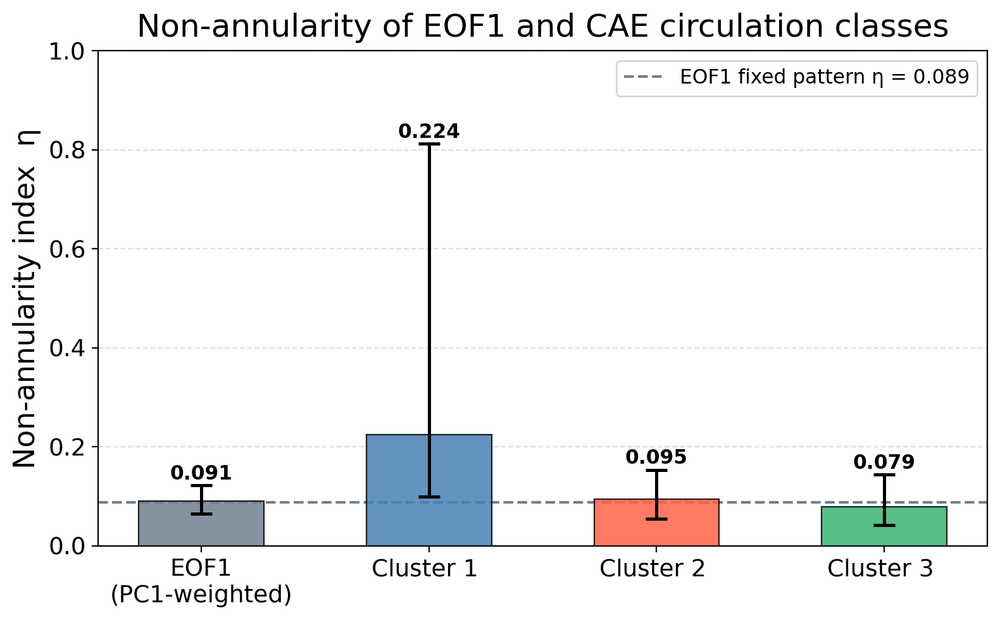

In [25]:
FS = fs_sizes(0.75)
fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
x = np.arange(K + 1)
bars = ax.bar(x, medians, color=["slategray", "steelblue", "tomato", "mediumseagreen"], width=0.55,
              alpha=0.85, edgecolor="black", linewidth=0.8, zorder=3)
ax.errorbar(x, medians, yerr=[lo, hi], fmt="none", color="black", capsize=6, capthick=1.8, elinewidth=1.8, zorder=4)
ax.axhline(eta_eof1, color="slategray", linestyle="--", linewidth=1.5,
           label=f"EOF1 fixed pattern \u03b7 = {eta_eof1:.3f}", zorder=2)
for bar, m, h in zip(bars, medians, hi):
    ax.text(bar.get_x() + bar.get_width() / 2, m + h + 0.003, f"{m:.3f}", ha="center", va="bottom",
            fontsize=FS["annot"], fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(["EOF1\n(PC1-weighted)"] + [f"Cluster {k + 1} " for k in range(K)], fontsize=FS["tick"])
ax.tick_params(axis="y", labelsize=FS["tick"])
ax.set_ylabel("Non-annularity index  \u03b7", fontsize=FS["label"])
ax.legend(fontsize=FS["annot"])
ax.set_ylim(0, 1)
ax.yaxis.grid(True, alpha=0.4, linestyle="--")
ax.set_axisbelow(True)
ax.set_title("Non-annularity of EOF1 and CAE circulation classes", fontsize=18, pad=8)
fig.tight_layout()
save_figure(fig, "annularity")

### Figure 7 -- transition probability against marginal occupancy

fraction of seeds with p < 0.05:
 [[0.3 0.4 0.7]
 [0.6 1.  0.8]
 [0.3 0.9 0.5]]


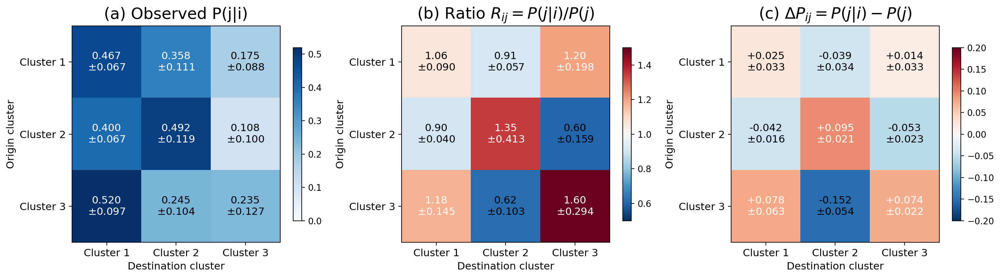

In [26]:
rng = np.random.default_rng(RNG_SEED)
obs_all = np.array([transition_matrix(members[s]["labels"]) for s in SEEDS])
p_all = np.array([p_values(o, shuffle_null(members[s]["labels"], rng, N_SHUFFLE)) for s, o in zip(SEEDS, obs_all)])
print("fraction of seeds with p < 0.05:\n", (p_all < 0.05).mean(axis=0))

occ = occupancy[:, None, :] / 100
fs = FS_TICK * 0.65
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=200)
for ax, arr, title, cmap, vmin, vmax, fmt in [
    (axes[0], obs_all, "(a) Observed P(j|i)", "Blues", 0.0, obs_all.mean(axis=0).max(), ".3f"),
    (axes[1], obs_all / occ, "(b) Ratio $R_{ij}=P(j|i)/P(j)$", "RdBu_r", 0.5, 1.5, ".2f"),
    (axes[2], obs_all - occ, "(c) $\\Delta P_{ij}=P(j|i)-P(j)$", "RdBu_r", -0.2, 0.2, "+.3f"),
]:
    m, sd = arr.mean(axis=0), arr.std(axis=0, ddof=1)
    plt.colorbar(ax.imshow(m, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"), ax=ax, shrink=0.8)
    ax.set_xticks(range(K))
    ax.set_xticklabels([f"Cluster {k + 1}" for k in range(K)], fontsize=fs)
    ax.set_yticks(range(K))
    ax.set_yticklabels([f"Cluster {k + 1}" for k in range(K)], fontsize=fs)
    ax.set_xlabel("Destination cluster", fontsize=fs)
    ax.set_ylabel("Origin cluster", fontsize=fs)
    ax.set_title(title, fontsize=18, pad=8)
    for (a, b), v in np.ndenumerate(m):
        ax.text(b, a, f"{v:{fmt}}\n$\\pm${sd[a, b]:.3f}", ha="center", va="center", fontsize=fs,
                color="black" if abs(v - vmin) < (vmax - vmin) * 0.6 else "white")
plt.tight_layout()
save_figure(fig, "transition")

### Figure S5 -- composites for all ten initialisations

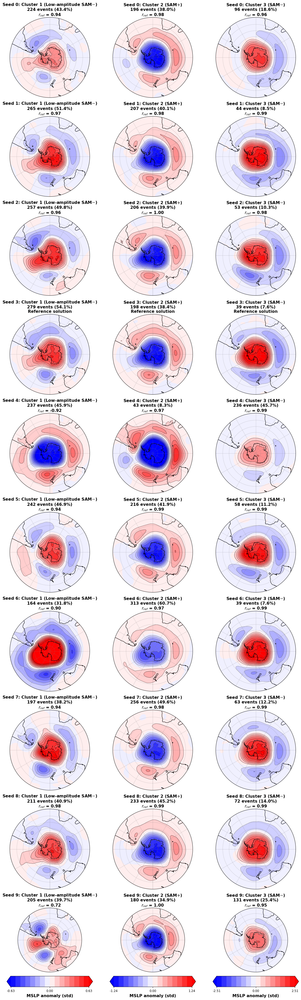

In [27]:
vmax_col = [np.percentile([np.percentile(np.abs(members[s]["composites"][k]), PCT) for s in SEEDS], PCT)
            for k in range(K)]

fig, axes = plt.subplots(len(SEEDS), K, figsize=(4.6 * K, 4.3 * len(SEEDS)), dpi=90, subplot_kw={"projection": SPS})
for r, s in enumerate(SEEDS):
    m = members[s]
    for k in range(K):
        n = (m["labels"] == k).sum()
        title = (f"Seed {s}: Cluster {k + 1} ({CLUSTER_NAMES[k]})\n{n} events ({occupancy[r, k]:.1f}%)\n"
                 + ("Reference solution" if s == REF_SEED else f"$r_{{ref}}$ = {m['r_ref'][k]:.2f}"))
        polar_map(axes[r, k], lons, lats, m["composites"][k], title=title, vmax=vmax_col[k],
                  add_colorbar=(r == len(SEEDS) - 1), edge_lat=-20, lon_labels=False, pole_fix=True,
                  contour_lw=0.6, fs=0.32, title_pad=14)
plt.tight_layout()
save_figure(fig, "ensemble")

### Figure S7 -- ensemble-mean composites against the leading EOFs and PCs

Spatial: area-weighted correlation of each composite with EOF 1-3. Temporal: correlation of the monthly projection onto each composite with PC 1-3.

In [28]:
W_AREA = np.broadcast_to(cos_w, data_phys.shape[1:]).ravel()
W_AREA = (W_AREA / W_AREA.sum()).astype(np.float32)
X_FLAT = data_phys.reshape(N, -1)


def corr_matrices(comps):
    S = np.array([[spatial_corr(c, eofs[m], cos_w) for m in range(3)] for c in comps])
    P = [X_FLAT @ (W_AREA * np.asarray(c, np.float32).ravel()) for c in comps]
    T = np.array([[np.corrcoef(p, pcs[:, m])[0, 1] for m in range(3)] for p in P])
    return S, T


S_ENS, T_ENS = corr_matrices(ens_mean)
S_SEEDS, T_SEEDS = map(np.array, zip(*[corr_matrices(members[s]["composites"]) for s in SEEDS]))
print("ensemble mean vs EOF1:", S_ENS[:, 0].round(3), " vs PC1:", T_ENS[:, 0].round(3))
print("per-seed vs EOF1:", [f"{m:+.2f} +/- {sd:.2f}" for m, sd in zip(S_SEEDS[:, :, 0].mean(0), S_SEEDS[:, :, 0].std(0))])

ensemble mean vs EOF1: [-0.955  0.982 -0.982]  vs PC1: [-0.991  0.994 -0.994]
per-seed vs EOF1: ['-0.71 +/- 0.57', '+0.98 +/- 0.01', '-0.97 +/- 0.03']


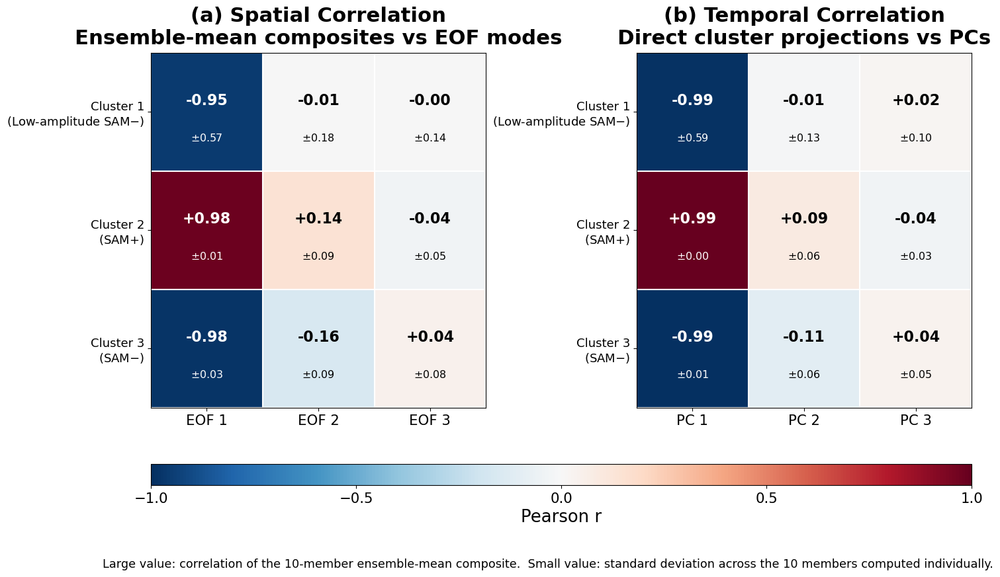

In [29]:
FS = fs_sizes(0.85)
row_labels = [f"Cluster {k + 1}\n({CLUSTER_NAMES[k]})" for k in range(K)]


def corr_heatmap(ax, mat, sd, title, col_labels):
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
    ax.set_xticks(range(3))
    ax.set_xticklabels(col_labels, fontsize=FS["tick"])
    ax.set_yticks(range(K))
    ax.set_yticklabels(row_labels, fontsize=FS["tick"] * 0.85)
    ax.set_xticks(np.arange(4) - 0.5, minor=True)
    ax.set_yticks(np.arange(K + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", length=0)
    for (r, c), v in np.ndenumerate(mat):
        color = "white" if abs(v) > 0.5 else "black"
        ax.text(c, r - 0.10, f"{v:+.2f}", ha="center", va="center", fontsize=FS["annot"] * 1.25,
                fontweight="bold", color=color)
        ax.text(c, r + 0.22, f"$\\pm${sd[r, c]:.2f}", ha="center", va="center", fontsize=FS["annot"] * 0.9, color=color)
    ax.set_title(title, fontsize=FS["title"], fontweight="bold", pad=10)
    return im


fig = plt.figure(figsize=(16, 8.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.06], hspace=0.30, wspace=0.45)
im = corr_heatmap(fig.add_subplot(gs[0, 0]), S_ENS, S_SEEDS.std(axis=0),
                  "(a) Spatial Correlation\nEnsemble-mean composites vs EOF modes", ["EOF 1", "EOF 2", "EOF 3"])
corr_heatmap(fig.add_subplot(gs[0, 1]), T_ENS, T_SEEDS.std(axis=0),
             "(b) Temporal Correlation\nDirect cluster projections vs PCs", ["PC 1", "PC 2", "PC 3"])
cb = fig.colorbar(im, cax=fig.add_subplot(gs[1, :]), orientation="horizontal")
cb.set_label("Pearson r", fontsize=FS["label"])
cb.set_ticks(np.linspace(-1, 1, 5))
cb.ax.tick_params(labelsize=FS["tick"])
fig.text(0.5, -0.02, "Large value: correlation of the 10-member ensemble-mean composite.  "
         "Small value: standard deviation across the 10 members computed individually.",
         ha="center", va="top", fontsize=FS["annot"])
save_figure(fig, "corr_direct_clusters_ensemble")

### Figure S11 -- composites before and after removing the rank-one EOF1

Least-squares EOF1 amplitude of each month under the area weighting, $a(t) = \langle x_t, e_1 \rangle / \langle e_1, e_1 \rangle$, so that $a(t)\,e_1$ is the rank-one reconstruction whatever the stored normalisation. Composite $x_t - a(t)\,e_1$ by class in every member and average.

In [30]:
w = np.broadcast_to(cos_w, data_phys.shape[1:]) / np.broadcast_to(cos_w, data_phys.shape[1:]).sum()
a = (X_FLAT.astype(np.float64) @ (w * eof1).ravel()) / np.sum(w * eof1 ** 2)

full = np.array([members[s]["composites"] for s in SEEDS], dtype=np.float64)
resid = np.array([[full[i, k] - a[members[s]["labels"] == k].mean() * eof1 for k in range(K)]
                  for i, s in enumerate(SEEDS)])
ens_full, ens_resid = full.mean(axis=0), resid.mean(axis=0)

ref = SEEDS.index(REF_SEED)
for k in range(K):
    amp_f, amp_r = area_weighted_rms(ens_full[k], lats), area_weighted_rms(ens_resid[k], lats)
    rr = [spatial_corr(resid[i, k], resid[ref, k], cos_w) for i in range(len(SEEDS)) if i != ref]
    print(f"Cluster {k + 1}: RMS {amp_f:.3f} -> {amp_r:.3f} ({100 * amp_r / amp_f:.0f}%), "
          f"r(resid, EOF1) = {spatial_corr(ens_resid[k], eof1, cos_w):+.3f}, "
          f"r_ref median {np.median(rr):.2f}, range {min(rr):+.2f} to {max(rr):+.2f}")

Cluster 1: RMS 0.144 -> 0.043 (30%), r(resid, EOF1) = +0.040, r_ref median 0.61, range -0.33 to +0.77
Cluster 2: RMS 0.468 -> 0.089 (19%), r(resid, EOF1) = -0.033, r_ref median 0.70, range -0.37 to +0.87
Cluster 3: RMS 0.813 -> 0.152 (19%), r(resid, EOF1) = +0.013, r_ref median 0.73, range +0.48 to +0.82


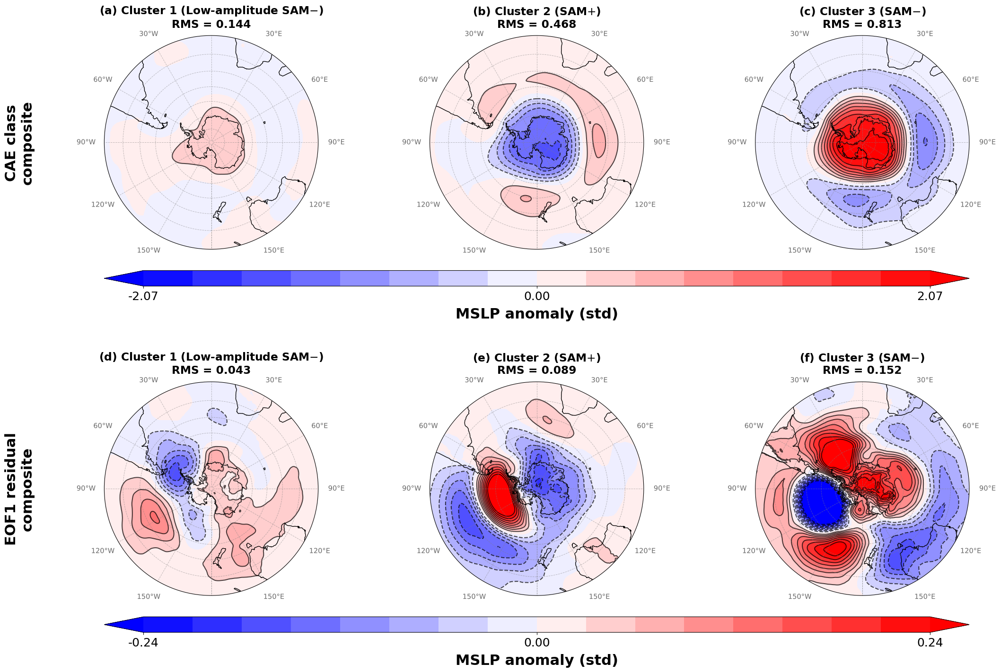

In [31]:
FS = fs_sizes(1.0)
fig = plt.figure(figsize=(22, 15))
axes, cfs, vmaxes = [], [], []
for row, field in enumerate([ens_full, ens_resid]):
    # one scale per row, so the residuals are not crushed by the full composites
    vmax = max(np.percentile(np.abs(f), PCT) for f in field)
    vmaxes.append(vmax)
    for k in range(K):
        ax = fig.add_subplot(2, K, row * K + k + 1, projection=SPS)
        axes.append(ax)
        cf, _ = polar_map(ax, lons, lats, field[k], vmax=vmax, add_colorbar=False, fs=0.42, title_pad=30,
                          title=(f"({'abcdef'[row * K + k]}) Cluster {k + 1} ({CLUSTER_NAMES[k]})\n"
                                 f"RMS = {area_weighted_rms(field[k], lats):.3f}"))
    cfs.append(cf)
plt.subplots_adjust(left=0.07, right=0.98, top=0.92, bottom=0.13, wspace=0.10, hspace=0.62)

for row, label in enumerate(["CAE class\ncomposite", "EOF1 residual\ncomposite"]):
    boxes = [ax.get_position() for ax in axes[row * K:(row + 1) * K]]
    x0, x1 = min(b.x0 for b in boxes), max(b.x1 for b in boxes)
    y0, y1 = min(b.y0 for b in boxes), max(b.y1 for b in boxes)
    fig.text(0.028, 0.5 * (y0 + y1), label, rotation=90, ha="center", va="center",
             fontsize=FS["label"], fontweight="bold")
    cbar = fig.colorbar(cfs[row], cax=fig.add_axes([x0, y0 - 0.030 - 0.022, x1 - x0, 0.022]), orientation="horizontal")
    ticks = np.linspace(-vmaxes[row], vmaxes[row], 3)
    cbar.set_ticks(ticks, labels=[f"{0.0 if abs(v) < 0.005 else v:.2f}" for v in ticks])
    cbar.ax.tick_params(labelsize=FS["tick"])
    cbar.set_label("MSLP anomaly (std)", fontsize=FS["label"], fontweight="bold", labelpad=8)
save_figure(fig, "eof1_residual_composites")

How much of each residual is EOF2?

In [32]:
e2 = eofs[1].astype(np.float64)
for k in range(K):
    amp = np.sum(w * ens_resid[k] * e2) / np.sum(w * e2 ** 2)
    share = np.sum(w * (amp * e2) ** 2) / np.sum(w * ens_resid[k] ** 2)
    per_seed = [spatial_corr(resid[i, k], e2, cos_w) for i in range(len(SEEDS))]
    print(f"Cluster {k + 1}: r(resid, EOF2) = {spatial_corr(ens_resid[k], e2, cos_w):+.2f}, "
          f"EOF2 share {100 * share:.0f}%, per seed {min(per_seed):+.2f} to {max(per_seed):+.2f}")
del full, resid, X_FLAT

Cluster 1: r(resid, EOF2) = -0.04, EOF2 share 0%, per seed -0.71 to +0.69
Cluster 2: r(resid, EOF2) = +0.77, EOF2 share 58%, per seed -0.42 to +0.85
Cluster 3: r(resid, EOF2) = -0.88, EOF2 share 77%, per seed -0.88 to -0.54


### Figure S12 -- Ward clustering of PC1, PC1-2 and PC1-3 against the CAE ensemble mean

PC1 only (std)   best-match r with the CAE classes: [-0.96  -0.983  0.983]
PC 1-2 (std)     best-match r with the CAE classes: [-0.963  0.978 -0.973]
PC 1-3 (std)     best-match r with the CAE classes: [-0.878 -0.882  0.905]


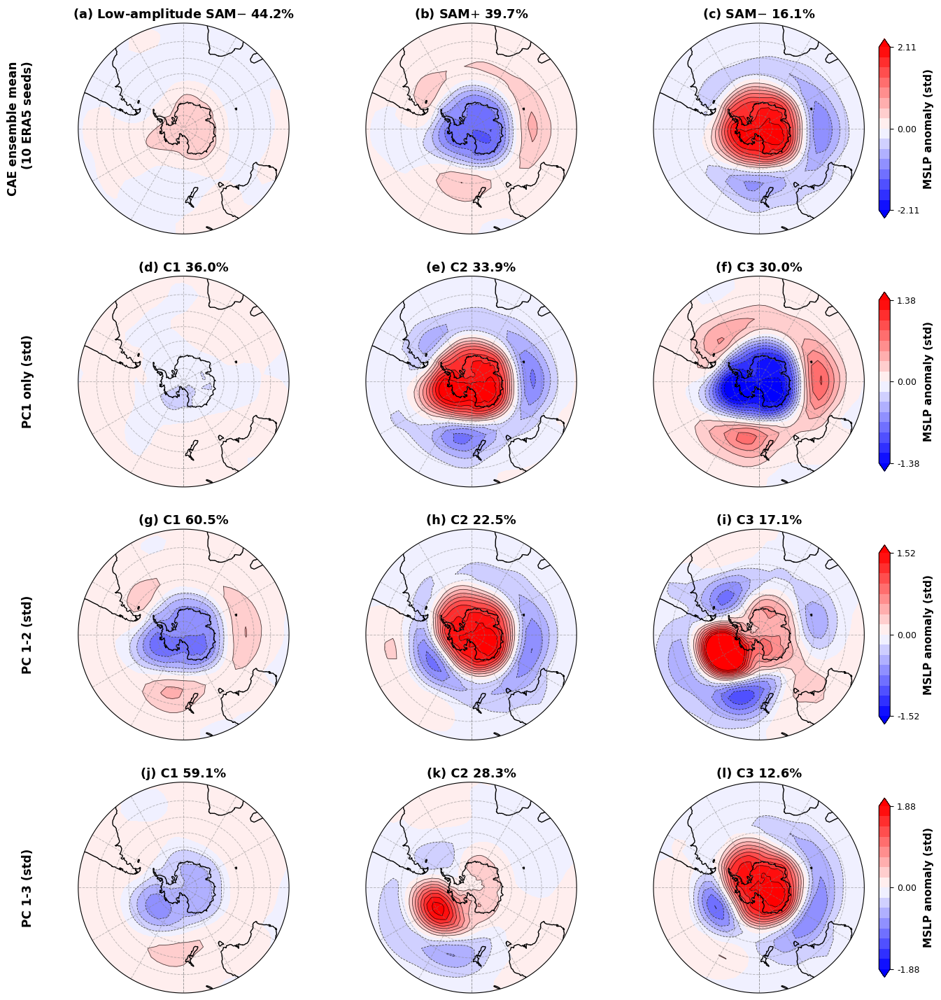

In [33]:
STEP = 20
lats_p, lons_p = lats[::STEP], lons[::STEP]
configs = [("CAE ensemble mean\n(10 ERA5 seeds)", list(ens_mean), occupancy.mean(axis=0))]
for n in (1, 2, 3):
    lab = ward_labels(pcs[:, :n], K)
    configs.append(("PC1 only (std)" if n == 1 else f"PC 1-{n} (std)",
                    [data_phys[lab == k].mean(axis=0) for k in range(K)], 100 * np.bincount(lab) / N))

for name, comps, _ in configs[1:]:
    r = [max((spatial_corr(e[::STEP, ::STEP], c[::STEP, ::STEP], cos_w[::STEP]) for c in comps), key=abs)
         for e in ens_mean]
    print(f"{name:<16} best-match r with the CAE classes: {np.round(r, 3)}")

fig, axes = plt.subplots(len(configs), K, figsize=(18, 4.5 * len(configs)), subplot_kw={"projection": SPS})
for r, (name, comps, occs) in enumerate(configs):
    vmax = max(np.percentile(np.abs(c[::STEP, ::STEP]), PCT) for c in comps)
    for k in range(K):
        cf, _ = polar_map(axes[r, k], lons_p, lats_p, comps[k][::STEP, ::STEP], vmax=vmax, add_colorbar=False,
                          title=f"({'abcdefghijkl'[r * K + k]}) {CLUSTER_NAMES[k] if r == 0 else f'C{k + 1}'} {occs[k]:.1f}%",
                          edge_lat=-20, lon_labels=False, contour_lw=0.6, fs=0.32, title_pad=16)
    # one colourbar per row: a row shares a colour scale, columns do not
    cb = fig.colorbar(cf, ax=axes[r, :].tolist(), orientation="vertical", shrink=0.85, pad=0.015, aspect=16)
    cb.set_ticks(np.linspace(-vmax, vmax, 3))
    cb.ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.2f"))
    cb.ax.tick_params(labelsize=FS_TICK * 0.5)
    cb.set_label("MSLP anomaly (std)", fontsize=FS_LABEL * 0.5, fontweight="bold")

fig.canvas.draw()
for r, (name, _, _) in enumerate(configs):
    pos = axes[r, 0].get_position()
    fig.text(pos.x0 - 0.035, (pos.y0 + pos.y1) / 2, name, fontsize=FS_LABEL * 0.55, fontweight="bold",
             va="center", ha="right", rotation=90)
save_figure(fig, "baseline_composites")

## 4. Architecture and latent size

### Figure S2 -- reconstruction loss by architecture and latent size

The losses are mean absolute errors in the standardized, sqrt(cos(lat))-weighted training units.

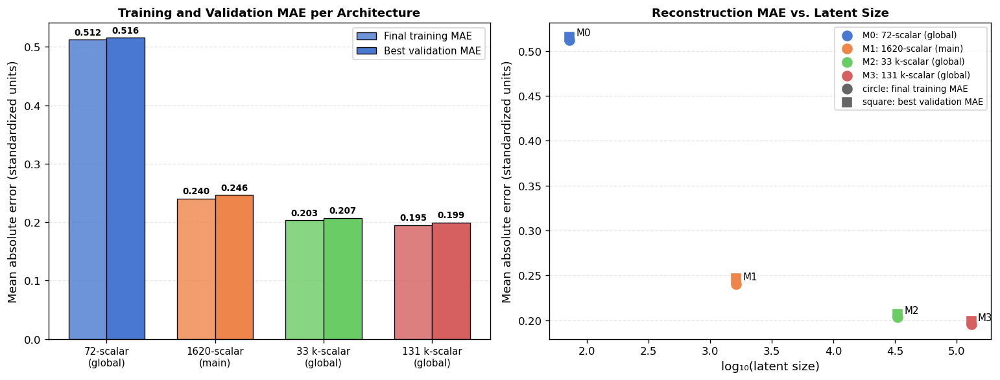

In [34]:
MODELS = [  # tag, label, latent size
    ("sam_autoencoder_1x_64_32_16_8_4_2_1-50epochs", "72-scalar\n(global)", 72),
    ("sam_autoencoder_1x_64_32_16_8_4_50epochs_cropped", "1620-scalar\n(main)", 1620),
    ("sam_autoencoder_1x_64_32_16_8_50epochs", "33 k-scalar\n(global)", 33120),
    ("sam_autoencoder_1x_32_16_8_50epochs", "131 k-scalar\n(global)", 131040),
]
summaries = [json.load(open(f"data/model_summaries/summary_{tag}.json")) for tag, _, _ in MODELS]
train = [s["final_loss"] for s in summaries]
val = [s["best_val_loss"] for s in summaries]
YLABEL = "Mean absolute error (standardized units)"
colors = ["#4878D0", "#EE854A", "#6ACC65", "#D65F5F"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
ax = axes[0]
x = np.arange(len(MODELS))
b1 = ax.bar(x - 0.175, train, 0.35, label="Final training MAE", color=[c + "cc" for c in colors],
            edgecolor="black", linewidth=0.8)
b2 = ax.bar(x + 0.175, val, 0.35, label="Best validation MAE", color=colors, edgecolor="black", linewidth=0.8)
for bar, v in zip([*b1, *b2], train + val):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", va="bottom",
            fontsize=8, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels([m[1] for m in MODELS], fontsize=9)
ax.set_title("Training and Validation MAE per Architecture", fontsize=11, fontweight="bold")

ax = axes[1]
for i, ((_, label, size), t, v, c) in enumerate(zip(MODELS, train, val, colors)):
    ax.scatter(np.log10(size), t, color=c, marker="o", s=80, zorder=4, label=f"M{i}: {label.replace(chr(10), ' ')}")
    ax.scatter(np.log10(size), v, color=c, marker="s", s=80, zorder=4)
    ax.annotate(f"M{i}", (np.log10(size), t), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.scatter([], [], color="0.4", marker="o", s=80, label="circle: final training MAE")
ax.scatter([], [], color="0.4", marker="s", s=80, label="square: best validation MAE")
ax.set_xlabel("log₁₀(latent size)", fontsize=11)
ax.set_title("Reconstruction MAE vs. Latent Size", fontsize=11, fontweight="bold")

for ax, fs in zip(axes, (9, 8)):
    ax.set_ylabel(YLABEL, fontsize=11)
    ax.legend(fontsize=fs)
    ax.yaxis.grid(True, alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)
fig.tight_layout()
save_figure(fig, "reconstruction_loss")

### Figure S3 -- composites as a function of latent dimension

Only the number of channels in the last encoder layer changes. Each seed-0 member is matched to the seed-3 reference of Section 3; 4 channels is the published configuration and is that ensemble's seed 0.

In [35]:
CHANNELS = [1, 2, 4, 8, 16]
LATENT_HW, INPUT_SCALARS = 9 * 45, 281 * 1440

sweep = {}
for ch in CHANNELS:
    if ch == 4:
        sweep[ch] = members[0]
        continue
    lab = ward_labels(load("encoded_all", f"sam_era5_latent{ch}ch_seed0", SWEEP_DIR), K)
    comps = [data_phys[lab == k].mean(axis=0) for k in range(K)]
    perm, corr = match_clusters(comps, ref_composites, cos_w)
    sweep[ch] = dict(composites=[comps[p] for p in perm], labels=np.argsort(perm)[lab], r_ref=corr[range(K), perm])

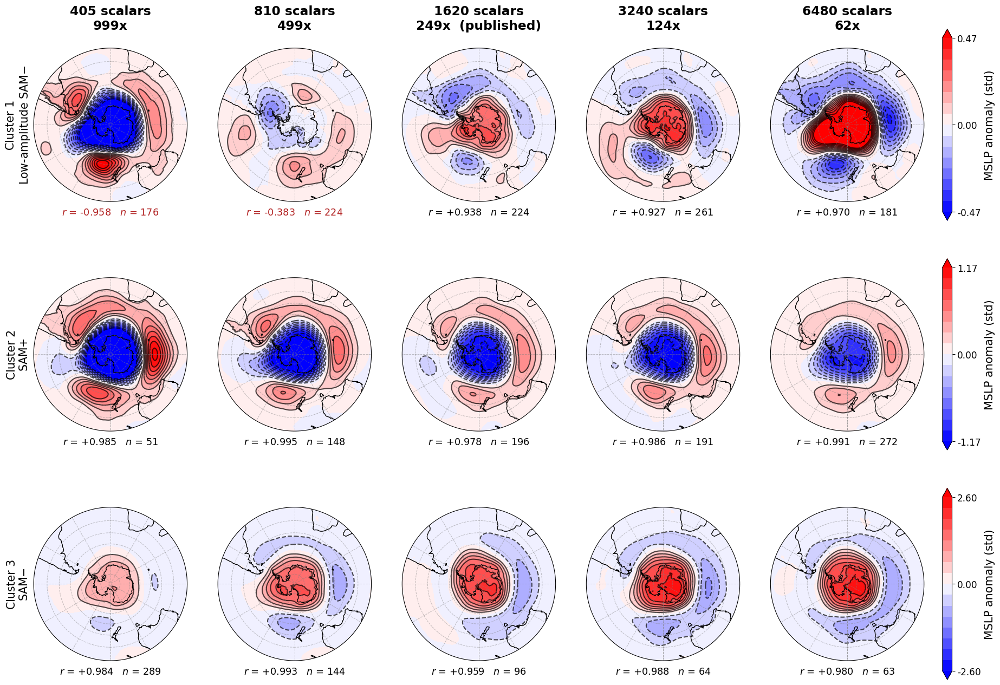

In [36]:
FS_MAP = 0.42
# one colour scale per row, from the reference composite, so a collapsed state cannot pass for a dipole
row_vmax = [np.percentile(np.abs(c), PCT) for c in ref_composites]

fig, axes = plt.subplots(K, len(CHANNELS), figsize=(4.4 * len(CHANNELS), 5.2 * K), subplot_kw={"projection": SPS})
row_cf = {}
for j, ch in enumerate(CHANNELS):
    m = sweep[ch]
    for k in range(K):
        ax = axes[k, j]
        title = (f"{LATENT_HW * ch} scalars\n{int(INPUT_SCALARS / (LATENT_HW * ch))}x"
                 + ("  (published)" if ch == 4 else "")) if k == 0 else ""
        # no perimeter labels: at five columns neighbouring panels' labels collide
        cf, _ = polar_map(ax, lons, lats, m["composites"][k], title=title, fs=FS_MAP, lon_labels=False,
                          vmax=row_vmax[k], add_colorbar=False)
        row_cf[k] = cf
        r = m["r_ref"][k]
        ax.text(0.5, -0.04, f"$r$ = {r:+.3f}   $n$ = {(m['labels'] == k).sum()}", transform=ax.transAxes,
                ha="center", va="top", fontsize=FS_ANNOT * 0.85, color="#B22222" if r < 0.5 else "black")

for k in range(K):
    axes[k, 0].text(-0.10, 0.5, f"Cluster {k + 1}\n{CLUSTER_NAMES[k]}", transform=axes[k, 0].transAxes,
                    rotation=90, ha="center", va="center", fontsize=FS_LABEL * FS_MAP * 1.6)
    cb = fig.colorbar(row_cf[k], ax=axes[k, :].tolist(), orientation="vertical",
                      fraction=0.016, pad=0.02, format="%.2f")
    cb.set_ticks(np.linspace(-row_vmax[k], row_vmax[k], 3))
    cb.set_label("MSLP anomaly (std)", fontsize=FS_LABEL * FS_MAP * 1.6)
    cb.ax.tick_params(labelsize=FS_TICK * FS_MAP * 1.6)
save_figure(fig, "latent_sweep_composites")